# Analisis dan Pemodelan Keterlambatan Penerbangan dari Houston Tahun 2011

## Pendahuluan

### Latar Belakang

Keterlambatan penerbangan merupakan salah satu permasalahan utama dalam industri penerbangan. Keterlambatan merugikan penumpang (waktu terbuang, koneksi penerbangan terlewat), maskapai (biaya bahan bakar, kru, dan kompensasi), serta bandara (kepadatan jadwal dan gerbang). Oleh karena itu, memahami pola keterlambatan dan faktor-faktor yang memengaruhinya penting untuk perencanaan operasional yang lebih baik.

Proyek ini menggunakan dataset **hflights** yang berisi 227.496 data penerbangan yang berangkat dari dua bandara di Houston (IAH dan HOU) selama tahun 2011. Data tersebut diolah melalui tahapan pemahaman data, penilaian kualitas, pembersihan, analisis eksploratif, pemodelan, evaluasi, hingga deployment model.

### Rumusan Masalah

**Analisis data (CLO 1):**
1. Bagaimana struktur dan kualitas data penerbangan, serta bagaimana penanganan missing values, outlier, dan inkonsistensi data?
2. **(EDA Q1)** Bagaimana distribusi keterlambatan keberangkatan dan kedatangan penerbangan?
3. **(EDA Q2)** Bagaimana hubungan antara keterlambatan keberangkatan dan keterlambatan kedatangan?
4. **(EDA Q3)** Bagaimana hubungan antara jarak penerbangan dan durasi penerbangan?
5. Variabel numerik apa saja yang saling berkorelasi kuat, dan apakah jarak atau durasi berkaitan dengan keterlambatan?

**Pemodelan (CLO 2):**

6. **(Klasifikasi)** Dapatkah status keterlambatan kedatangan (terlambat > 15 menit atau tidak) diprediksi dari informasi jadwal sebelum pesawat berangkat?
7. **(Prediksi/Regresi)** Seberapa akurat besar keterlambatan kedatangan (dalam menit) dapat diprediksi setelah pesawat berangkat?
8. **(Pengelompokan)** Bagaimana bandara tujuan dapat dikelompokkan berdasarkan karakteristik rute dan pola keterlambatannya?
9. Bagaimana model terbaik dapat disimpan dan digunakan kembali untuk memprediksi data penerbangan baru (deployment)?

### Tujuan

1. Memahami struktur data serta memastikan kualitas data melalui proses validasi dan cleaning.
2. Menemukan pola keterlambatan berdasarkan maskapai, waktu, bandara, dan rute melalui analisis data dan EDA.
3. Mengukur hubungan antarvariabel menggunakan analisis korelasi.
4. Membangun dan mengevaluasi model **klasifikasi**, **prediksi (regresi)**, dan **pengelompokan (clustering)**.
5. Menyimpan model terbaik dan menyediakan fungsi prediksi yang dapat digunakan kembali (deployment).

### Perangkat yang Digunakan

| Perangkat | Fungsi dalam Proyek | Alasan Dipilih |
|---|---|---|
| **Python 3** | Bahasa pemrograman utama | Ekosistem data science paling lengkap dan banyak digunakan |
| **Google Colab** | Lingkungan menjalankan notebook | Gratis, berbasis cloud, library sudah terpasang, mudah dibagikan |
| **pandas** | Membaca CSV, cleaning, agregasi, dan manipulasi tabel | Struktur DataFrame memudahkan pengolahan data tabular berukuran besar |
| **NumPy** | Perhitungan numerik dan operasi array | Cepat dan menjadi dasar pandas maupun scikit-learn |
| **Matplotlib** | Membuat grafik dasar (histogram, bar, scatter) | Fleksibel untuk mengatur detail visualisasi |
| **Seaborn** | Visualisasi statistik (boxplot, heatmap, regplot) | Sintaks ringkas dan tampilan statistik yang informatif |
| **scikit-learn** | Preprocessing, pembagian data, pemodelan, dan evaluasi model | Menyediakan algoritma klasifikasi, regresi, clustering, dan metrik evaluasi dalam satu API yang konsisten |
| **joblib** | Menyimpan dan memuat model (deployment) | Efisien untuk menyimpan objek scikit-learn berukuran besar |
| **ipywidgets** | Form input interaktif untuk mencoba model | Tersedia di Colab sehingga model dapat dicoba tanpa menulis kode |

### Alur Pengerjaan

| Tahap | Kegiatan |
|---|---|
| 1. Data Understanding | Memuat data, melihat struktur, tipe data, missing values, dan status penerbangan |
| 2. Data Quality Assessment | Memeriksa rentang nilai, kategori, validitas tanggal, format waktu, dan konsistensi durasi |
| 3. Data Cleaning | Menangani missing values, outlier, konsistensi, validitas, duplikasi, dan keputusan imputasi |
| 4. Data Analysis | Menganalisis volume dan keterlambatan berdasarkan maskapai, waktu, bandara, dan rute |
| EDA Q1–Q3 & Korelasi | Menjawab pertanyaan EDA dan mengukur hubungan antarvariabel |
| 5. Modeling & Evaluasi | Klasifikasi, prediksi (regresi), dan pengelompokan beserta evaluasinya |
| 6. Deployment | Menyimpan model dan menyediakan fungsi prediksi untuk data baru |

## 1. Data Understanding

Proyek ini bertujuan untuk melakukan pengolahan dan analisis
data penerbangan berdasarkan jadwal dan performa penerbangan.

Analisis difokuskan pada keterlambatan penerbangan, jarak,
durasi perjalanan, serta faktor operasional lainnya.

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Library berhasil diimport!")

Library berhasil diimport!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving dataset_plane.zip to dataset_plane.zip


In [17]:
import zipfile
import os

# Ekstrak dataset
zip_path = '/content/dataset_plane.zip'
extract_path = '/content/dataset_plane'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")

Dataset berhasil diekstrak!


In [18]:
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/dataset_plane/hflights.csv


In [5]:
# Membaca dataset CSV
df = pd.read_csv('/content/dataset_plane/hflights.csv')

print("Dataset berhasil dimuat!")
print("Ukuran dataset:", df.shape)

Dataset berhasil dimuat!
Ukuran dataset: (227496, 21)


In [6]:
display(df.head())

,Year,Month,DayofMonth,DayOfWeek,DepTime,ArrTime,UniqueCarrier,FlightNum,TailNum,ActualElapsedTime,AirTime,ArrDelay,DepDelay,Origin,Dest,Distance,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted
0,2011,1,1,6,1400.0,1500.0,AA,428,N576AA,60.0,40.0,-10.0,0.0,IAH,DFW,224,7.0,13.0,0,NaN,0
1,2011,1,2,7,1401.0,1501.0,AA,428,N557AA,60.0,45.0,-9.0,1.0,IAH,DFW,224,6.0,9.0,0,NaN,0
2,2011,1,3,1,1352.0,1502.0,AA,428,N541AA,70.0,48.0,-8.0,-8.0,IAH,DFW,224,5.0,17.0,0,NaN,0
3,2011,1,4,2,1403.0,1513.0,AA,428,N403AA,70.0,39.0,3.0,3.0,IAH,DFW,224,9.0,22.0,0,NaN,0
4,2011,1,5,3,1405.0,1507.0,AA,428,N492AA,62.0,44.0,-3.0,5.0,IAH,DFW,224,9.0,9.0,0,NaN,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 227496 entries, 0 to 227495
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Year               227496 non-null  int64  
 1   Month              227496 non-null  int64  
 2   DayofMonth         227496 non-null  int64  
 3   DayOfWeek          227496 non-null  int64  
 4   DepTime            224591 non-null  float64
 5   ArrTime            224430 non-null  float64
 6   UniqueCarrier      227496 non-null  str    
 7   FlightNum          227496 non-null  int64  
 8   TailNum            226701 non-null  str    
 9   ActualElapsedTime  223874 non-null  float64
 10  AirTime            223874 non-null  float64
 11  ArrDelay           223874 non-null  float64
 12  DepDelay           224591 non-null  float64
 13  Origin             227496 non-null  str    
 14  Dest               227496 non-null  str    
 15  Distance           227496 non-null  int64  
 16  TaxiIn       

In [8]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Year,227496.0,NaN,NaN,NaN,2011.0,0.0,2011.0,2011.0,2011.0,2011.0,2011.0
Month,227496.0,NaN,NaN,NaN,6.513662,3.417676,1.0,4.0,7.0,9.0,12.0
DayofMonth,227496.0,NaN,NaN,NaN,15.737446,8.782705,1.0,8.0,16.0,23.0,31.0
DayOfWeek,227496.0,NaN,NaN,NaN,3.947691,1.990272,1.0,2.0,4.0,6.0,7.0
DepTime,224591.0,NaN,NaN,NaN,1395.755614,448.322238,1.0,1021.0,1416.0,1801.0,2400.0
ArrTime,224430.0,NaN,NaN,NaN,1578.254106,472.401715,1.0,1215.0,1617.0,1953.0,2400.0
UniqueCarrier,227496,15,XE,73053,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FlightNum,227496.0,NaN,NaN,NaN,1961.663141,1430.793403,1.0,855.0,1696.0,2755.0,7290.0
TailNum,226701,3319,N14945,971,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ActualElapsedTime,223874.0,NaN,NaN,NaN,129.323745,59.285838,34.0,77.0,128.0,165.0,575.0


### Struktur Data

Dataset yang digunakan adalah **hflights**, yaitu data seluruh penerbangan yang berangkat dari dua bandara di Houston, Amerika Serikat (**IAH** – George Bush Intercontinental dan **HOU** – William P. Hobby) selama tahun **2011**. Dataset terdiri dari **227.496 baris** (setiap baris = satu penerbangan) dan **21 kolom**.

| No | Kolom | Tipe | Jenis | Keterangan |
|---|---|---|---|---|
| 1 | Year | int | Numerik (waktu) | Tahun penerbangan (seluruhnya 2011) |
| 2 | Month | int | Kategorikal (kode) | Bulan penerbangan (1–12) |
| 3 | DayofMonth | int | Kategorikal (kode) | Tanggal dalam bulan (1–31) |
| 4 | DayOfWeek | int | Kategorikal (kode) | Hari dalam minggu (1 = Senin, …, 7 = Minggu) |
| 5 | DepTime | float | Numerik (waktu) | Jam keberangkatan aktual, format HHMM waktu lokal |
| 6 | ArrTime | float | Numerik (waktu) | Jam kedatangan aktual, format HHMM waktu lokal |
| 7 | UniqueCarrier | object | Kategorikal | Kode maskapai (contoh: XE, CO, WN) |
| 8 | FlightNum | int | Identitas | Nomor penerbangan |
| 9 | TailNum | object | Identitas | Nomor registrasi pesawat |
| 10 | ActualElapsedTime | float | Numerik | Total durasi aktual penerbangan, termasuk taxi (menit) |
| 11 | AirTime | float | Numerik | Durasi pesawat berada di udara (menit) |
| 12 | ArrDelay | float | Numerik | Keterlambatan kedatangan (menit, negatif = lebih awal) |
| 13 | DepDelay | float | Numerik | Keterlambatan keberangkatan (menit, negatif = lebih awal) |
| 14 | Origin | object | Kategorikal | Kode bandara asal (IAH / HOU) |
| 15 | Dest | object | Kategorikal | Kode bandara tujuan |
| 16 | Distance | int | Numerik | Jarak penerbangan (mil) |
| 17 | TaxiIn | float | Numerik | Waktu taxi setelah mendarat (menit) |
| 18 | TaxiOut | float | Numerik | Waktu taxi sebelum lepas landas (menit) |
| 19 | Cancelled | int | Biner | Status pembatalan (1 = dibatalkan, 0 = tidak) |
| 20 | CancellationCode | object | Kategorikal | Alasan pembatalan: A = maskapai, B = cuaca, C = sistem penerbangan nasional, D = keamanan |
| 21 | Diverted | int | Biner | Status pengalihan (1 = dialihkan, 0 = tidak) |

Variabel utama yang dianalisis adalah **DepDelay** dan **ArrDelay** (keterlambatan), didukung oleh variabel jarak (**Distance**), durasi (**AirTime**, **ActualElapsedTime**), waktu operasional darat (**TaxiIn**, **TaxiOut**), serta variabel kategorikal maskapai, waktu, dan bandara.

In [9]:
# Merangkum struktur setiap kolom pada dataset
structure_summary = pd.DataFrame({
    'Tipe Data': df.dtypes.astype(str),
    'Jumlah Non-Null': df.notna().sum(),
    'Jumlah Missing': df.isna().sum(),
    'Jumlah Nilai Unik': df.nunique(),
    'Contoh Nilai': df.iloc[0]
})

# Menampilkan ringkasan struktur data
display(structure_summary)

# Menghitung jumlah kolom berdasarkan tipe data
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
print("Kolom numerik     (" + str(len(numeric_cols)) + "):", numeric_cols)
print("Kolom kategorikal (" + str(len(categorical_cols)) + "):", categorical_cols)

,Tipe Data,Jumlah Non-Null,Jumlah Missing,Jumlah Nilai Unik,Contoh Nilai
Year,int64,227496,0,1,2011
Month,int64,227496,0,12,1
DayofMonth,int64,227496,0,31,1
DayOfWeek,int64,227496,0,7,6
DepTime,float64,224591,2905,1207,1400.0
ArrTime,float64,224430,3066,1283,1500.0
UniqueCarrier,str,227496,0,15,AA
FlightNum,int64,227496,0,3740,428
TailNum,str,226701,795,3319,N576AA
ActualElapsedTime,float64,223874,3622,435,60.0


Jumlah baris : 227496
Jumlah kolom : 21
Kolom numerik     (16): ['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'DepTime', 'ArrTime', 'FlightNum', 'ActualElapsedTime', 'AirTime', 'ArrDelay', 'DepDelay', 'Distance', 'TaxiIn', 'TaxiOut', 'Cancelled', 'Diverted']
Kolom kategorikal (5): ['UniqueCarrier', 'TailNum', 'Origin', 'Dest', 'CancellationCode']


### Kesimpulan Struktur Data

Dataset memiliki 227.496 baris dan 21 kolom yang terdiri dari 16 kolom bertipe numerik dan 5 kolom bertipe teks (kategorikal). Meskipun bertipe numerik, kolom Month, DayofMonth, dan DayOfWeek berfungsi sebagai kode waktu, kolom FlightNum sebagai identitas, serta kolom Cancelled dan Diverted sebagai penanda status biner. Oleh karena itu, kolom-kolom tersebut tidak diperlakukan sebagai besaran kontinu dalam analisis korelasi. Kolom Year hanya memiliki satu nilai (2011) sehingga tidak memberikan variasi informasi.

In [10]:
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

display(missing_values.sort_values(
    by='Missing Values',
    ascending=False
))

,Missing Values,Percentage (%)
CancellationCode,224523,98.693164
ArrDelay,3622,1.592116
ActualElapsedTime,3622,1.592116
AirTime,3622,1.592116
TaxiIn,3066,1.347716
ArrTime,3066,1.347716
TaxiOut,2947,1.295407
DepTime,2905,1.276946
DepDelay,2905,1.276946
TailNum,795,0.349457


In [11]:
print("Jumlah duplikasi:", df.duplicated().sum())

Jumlah duplikasi:

 0


In [12]:
# Menghitung jumlah penerbangan berdasarkan status
print("Status Penerbangan")
print("===================")

print("Total penerbangan:", len(df))
print("Penerbangan dibatalkan:", df['Cancelled'].sum())
print("Penerbangan dialihkan:", df['Diverted'].sum())
print("Penerbangan normal:",
      len(df) - df['Cancelled'].sum() - df['Diverted'].sum())

Status Penerbangan
Total penerbangan: 227496
Penerbangan dibatalkan: 2973
Penerbangan dialihkan: 649
Penerbangan normal: 223874


In [13]:
#Melihat alasan pembatalan
display(
    df['CancellationCode']
    .value_counts(dropna=False)
    .rename_axis('Cancellation Code')
    .reset_index(name='Jumlah')
)

,Cancellation Code,Jumlah
0,NaN,224523
1,B,1652
2,A,1202
3,C,118
4,D,1


In [14]:
#Membandingkan status penerbangan dengan missing values
status_missing = df.groupby(
    ['Cancelled', 'Diverted']
).agg(
    Total_Penerbangan=('FlightNum', 'count'),
    Missing_DepDelay=('DepDelay', lambda x: x.isna().sum()),
    Missing_ArrDelay=('ArrDelay', lambda x: x.isna().sum()),
    Missing_AirTime=('AirTime', lambda x: x.isna().sum())
)

display(status_missing)

Total_Penerbangan  Missing_DepDelay  Missing_ArrDelay  \
Cancelled Diverted                                                          
0         0                    223874                 0                 0   
          1                       649                 0               649   
1         0                      2973              2905              2973   

                    Missing_AirTime  
Cancelled Diverted                   
0         0                       0  
          1                     649  
1         0                    2973

In [15]:
#Memeriksa distribusi delay
display(
    df[['DepDelay', 'ArrDelay']].describe().T
)

,count,mean,std,min,25%,50%,75%,max
DepDelay,224591.0,9.444951,28.803615,-33.0,-3.0,0.0,9.0,981.0
ArrDelay,223874.0,7.094334,30.708516,-70.0,-8.0,0.0,11.0,978.0


### Kesimpulan Validasi Status Penerbangan

Berdasarkan hasil pemeriksaan terhadap 227.496 data penerbangan, terdapat 223.874 penerbangan normal, 2.973 penerbangan dibatalkan, dan 649 penerbangan dialihkan. Pembatalan penerbangan paling banyak disebabkan oleh faktor cuaca berdasarkan kode pembatalan B.

Hasil pemeriksaan juga menunjukkan bahwa missing values pada beberapa kolom berkaitan dengan status penerbangan. Penerbangan yang dibatalkan dan dialihkan memiliki sejumlah informasi operasional yang memang tidak tersedia, seperti waktu kedatangan dan durasi penerbangan.

Selain itu, rata-rata keterlambatan keberangkatan sebesar 9,44 menit dan keterlambatan kedatangan sebesar 7,09 menit. Ditemukan pula nilai keterlambatan maksimum yang cukup tinggi sehingga perlu diperiksa lebih lanjut sebagai kandidat outlier.

Dengan demikian, dataset memiliki struktur dan informasi yang cukup baik untuk dilanjutkan ke tahap penilaian kualitas data dan Data Cleaning. Penanganan missing values nantinya perlu mempertimbangkan status penerbangan agar tidak menghilangkan informasi yang sebenarnya valid.

## Step 2 — Data Quality Assessment

In [16]:
# Memeriksa rentang nilai pada kolom numerik
numeric_columns = df.select_dtypes(include=np.number).columns

# Menghitung nilai minimum dan maksimum setiap kolom
range_check = pd.DataFrame({
    'Minimum': df[numeric_columns].min(),
    'Maximum': df[numeric_columns].max(),
    'Mean': df[numeric_columns].mean()
})

# Menampilkan hasil pemeriksaan
display(range_check)

,Minimum,Maximum,Mean
Year,2011.0,2011.0,2011.000000
Month,1.0,12.0,6.513662
DayofMonth,1.0,31.0,15.737446
DayOfWeek,1.0,7.0,3.947691
DepTime,1.0,2400.0,1395.755614
ArrTime,1.0,2400.0,1578.254106
FlightNum,1.0,7290.0,1961.663141
ActualElapsedTime,34.0,575.0,129.323745
AirTime,11.0,549.0,108.142335
ArrDelay,-70.0,978.0,7.094334


In [17]:
# Memeriksa jumlah kategori unik pada kolom kategorikal
categorical_columns = df.select_dtypes(include='object').columns

# Menghitung jumlah kategori unik
for column in categorical_columns:
    print(f"\nKolom: {column}")
    print("Jumlah kategori:", df[column].nunique())
    print(df[column].value_counts(dropna=False).head(10))


Kolom: UniqueCarrier
Jumlah kategori: 15
UniqueCarrier
XE    73053
CO    70032
WN    45343
OO    16061
MQ     4648
US     4082
AA     3244
DL     2641
EV     2204
FL     2139
Name: count, dtype: int64

Kolom: TailNum
Jumlah kategori: 3319
TailNum
N14945    971
N15926    960
N16927    951
N12946    948
N14942    946
N14937    946
N15948    942
N14938    935
N13935    934
N14943    934
Name: count, dtype: int64

Kolom: Origin
Jumlah kategori: 2
Origin
IAH    175197
HOU     52299
Name: count, dtype: int64

Kolom: Dest
Jumlah kategori: 116
Dest
DAL    9820
ATL    7886
MSY    6823
DFW    6653
LAX    6064
DEN    5920
ORD    5748
PHX    5096
AUS    5022
SAT    4893
Name: count, dtype: int64

Kolom: CancellationCode
Jumlah kategori: 4
CancellationCode
NaN    224523
B        1652
A        1202
C         118
D           1
Name: count, dtype: int64


In [18]:
# Memeriksa kombinasi status penerbangan
status_check = df.groupby(
    ['Cancelled', 'Diverted']
).size().reset_index(name='Jumlah')

# Menampilkan kombinasi status
display(status_check)

,Cancelled,Diverted,Jumlah
0,0,0,223874
1,0,1,649
2,1,0,2973


## Kesimpulan Sementara Step 2
Berdasarkan tiga pemeriksaan sebelumnya, dataset memiliki 227.496 baris dan 21 kolom, tanpa duplikasi. Rentang sebagian besar variabel numerik terlihat wajar, tetapi terdapat beberapa nilai ekstrem pada variabel keterlambatan dan waktu operasional yang perlu diperiksa lebih lanjut.

Kolom kategorikal memiliki variasi yang cukup baik, dengan 15 maskapai, 2 bandara asal, dan 116 bandara tujuan. Kombinasi status penerbangan juga konsisten, karena tidak ditemukan penerbangan yang sekaligus dibatalkan dan dialihkan.

Pemeriksaan lanjutan terhadap validitas tanggal, format waktu, dan konsistensi durasi masih diperlukan sebelum menentukan strategi Data Cleaning.

In [19]:
# Memeriksa validitas kombinasi tahun, bulan, dan tanggal
flight_date = pd.to_datetime(
    df[['Year', 'Month', 'DayofMonth']].rename(
        columns={
            'Year': 'year',
            'Month': 'month',
            'DayofMonth': 'day'
        }
    ),
    errors='coerce'
)

# Menghitung tanggal yang tidak valid
invalid_dates = flight_date.isna().sum()

print("Jumlah tanggal tidak valid:", invalid_dates)
print("Jumlah tanggal valid:", flight_date.notna().sum())

Jumlah tanggal tidak valid: 0
Jumlah tanggal valid: 227496


In [20]:
# Fungsi untuk memeriksa format waktu HHMM
def check_time(value):
    if pd.isna(value):
        return True

    # Mengubah nilai menjadi integer
    value = int(value)

    # Memisahkan jam dan menit
    hour = value // 100
    minute = value % 100

    # Memeriksa batas jam dan menit
    return (
        (0 <= hour <= 23 and 0 <= minute <= 59)
        or value == 2400
    )

# Memeriksa waktu keberangkatan dan kedatangan
invalid_dep_time = (~df['DepTime'].apply(check_time)).sum()
invalid_arr_time = (~df['ArrTime'].apply(check_time)).sum()

print("DepTime tidak valid:", invalid_dep_time)
print("ArrTime tidak valid:", invalid_arr_time)

DepTime tidak valid: 0
ArrTime tidak valid: 0


In [21]:
# Memeriksa hubungan antara durasi penerbangan dan waktu operasional
duration_check = df[
    ['ActualElapsedTime', 'AirTime', 'TaxiIn', 'TaxiOut']
].dropna().copy()

# Menghitung total durasi berdasarkan komponen waktu
duration_check['CalculatedElapsedTime'] = (
    duration_check['AirTime']
    + duration_check['TaxiIn']
    + duration_check['TaxiOut']
)

# Menghitung selisih durasi aktual dan hasil perhitungan
duration_check['TimeDifference'] = (
    duration_check['ActualElapsedTime']
    - duration_check['CalculatedElapsedTime']
)

# Menampilkan statistik selisih durasi
display(duration_check['TimeDifference'].describe())

# Menghitung jumlah data dengan selisih durasi
print(
    "Jumlah data dengan selisih durasi:",
    (duration_check['TimeDifference'] != 0).sum()
)

count    223874.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: TimeDifference, dtype: float64

Jumlah data dengan selisih durasi: 0


### Kesimpulan Data Quality Assessment

Berdasarkan hasil pemeriksaan kualitas data, dataset penerbangan yang terdiri dari 227.496 baris dan 21 kolom menunjukkan kondisi yang cukup baik. Tidak ditemukan duplikasi baris maupun tanggal penerbangan yang tidak valid.

Pemeriksaan format waktu pada kolom DepTime dan ArrTime juga tidak menemukan nilai yang tidak sesuai dengan format HHMM. Selain itu, pemeriksaan konsistensi durasi menunjukkan bahwa penjumlahan AirTime, TaxiIn, dan TaxiOut sama dengan ActualElapsedTime pada seluruh 223.874 baris yang memiliki data lengkap untuk keempat kolom tersebut.

Kombinasi status penerbangan juga menunjukkan pola yang konsisten antara penerbangan normal, dibatalkan, dan dialihkan. Meskipun demikian, masih terdapat missing values pada beberapa kolom dan nilai ekstrem pada variabel keterlambatan yang perlu ditinjau lebih lanjut.

Dengan demikian, dataset memiliki kualitas dasar yang baik, tetapi tetap memerlukan proses Data Cleaning untuk menangani missing values dan mengevaluasi nilai-nilai ekstrem sebelum digunakan dalam analisis lebih lanjut.

## Step 3 — Data Cleaning

Sebelum melakukan proses Data Cleaning, dataset asli (df) disalin terlebih dahulu menjadi dataset baru (df_clean) menggunakan metode .copy().

Tujuan membuat salinan dataset:

Melindungi data asli: Dataset mentah (df) tetap dipertahankan tanpa perubahan selama proses Data Cleaning.

Menghindari kehilangan data: Jika terjadi kesalahan saat proses cleaning, kita masih memiliki dataset asli sebagai sumber data awal.

Memudahkan perbandingan: Dataset sebelum dan sesudah cleaning dapat dibandingkan untuk mengetahui perubahan yang terjadi.

Dengan demikian, dataset df digunakan sebagai data referensi awal, sedangkan df_clean digunakan untuk proses pengolahan dan pembersihan data selanjutnya.

In [22]:
# Membuat salinan dataset untuk proses cleaning
df_clean = df.copy()

# Memastikan dataset mentah tetap utuh
print("Ukuran dataset mentah:", df.shape)
print("Ukuran dataset cleaning:", df_clean.shape)

Ukuran dataset mentah: (227496, 21)
Ukuran dataset cleaning: (227496, 21)



Proses penyalinan dataset berhasil dilakukan menggunakan metode `.copy()`. Dataset mentah (`df`) dan dataset untuk proses cleaning (`df_clean`) masing-masing memiliki 227.496 baris dan 21 kolom. Dengan demikian, dataset asli tetap terjaga dan proses Data Cleaning selanjutnya dapat dilakukan pada salinan dataset tanpa memengaruhi data sumber.

In [23]:
# Menghitung jumlah missing values pada setiap kolom
missing_before = df_clean.isnull().sum()

# Menghitung persentase missing values
missing_percentage = (
    df_clean.isnull().sum() / len(df_clean) * 100
)

# Membuat tabel ringkasan missing values
missing_summary = pd.DataFrame({
    'Missing Values': missing_before,
    'Percentage (%)': missing_percentage
})

# Mengurutkan berdasarkan jumlah missing values terbanyak
missing_summary = missing_summary.sort_values(
    by='Missing Values',
    ascending=False
)

# Menampilkan hasil pemeriksaan
display(missing_summary)

,Missing Values,Percentage (%)
CancellationCode,224523,98.693164
ArrDelay,3622,1.592116
ActualElapsedTime,3622,1.592116
AirTime,3622,1.592116
TaxiIn,3066,1.347716
ArrTime,3066,1.347716
TaxiOut,2947,1.295407
DepTime,2905,1.276946
DepDelay,2905,1.276946
TailNum,795,0.349457


Analisis setiap kolom

CancellationCode	224.523	Kosong pada penerbangan yang tidak dibatalkan

ArrDelay	3.622	Berkaitan dengan penerbangan batal dan dialihkan

ActualElapsedTime	3.622	Durasi aktual tidak tersedia pada penerbangan tertentu

AirTime	3.622	Waktu di udara tidak tersedia pada penerbangan tertentu

TaxiIn	3.066	Informasi operasional tidak tersedia

ArrTime	3.066	Waktu kedatangan tidak tersedia

TaxiOut	2.947	Informasi operasional tidak tersedia

DepTime	2.905	Waktu keberangkatan tidak tersedia

DepDelay	2.905	Informasi keterlambatan keberangkatan tidak tersedia

TailNum	795	Identitas pesawat tidak tercatat

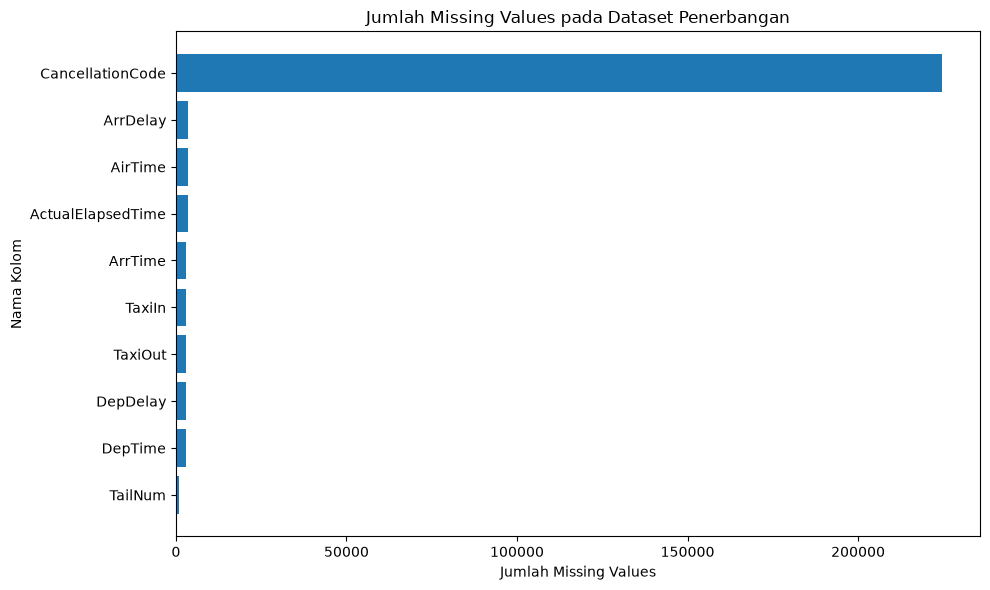

In [24]:
# Mengambil kolom yang memiliki missing values
missing_plot = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(
    by='Missing Values',
    ascending=True
)

# Membuat ukuran gambar
plt.figure(figsize=(10, 6))

# Membuat grafik batang horizontal
plt.barh(
    missing_plot.index,
    missing_plot['Missing Values']
)

# Memberikan judul dan label
plt.title('Jumlah Missing Values pada Dataset Penerbangan')
plt.xlabel('Jumlah Missing Values')
plt.ylabel('Nama Kolom')

# Mengatur tata letak grafik
plt.tight_layout()

# Menampilkan grafik
plt.show()

### Kesimpulan Analisis Missing Values Sebelum Cleaning

Berdasarkan pemeriksaan terhadap dataset penerbangan, ditemukan 10 kolom yang memiliki missing values dan 11 kolom tanpa missing values. Missing values terbanyak terdapat pada kolom CancellationCode sebanyak 224.523 data atau 98,69%.

Namun, nilai kosong pada CancellationCode tidak langsung dianggap sebagai kerusakan data karena kolom tersebut berkaitan dengan alasan pembatalan penerbangan. Sementara itu, kolom ArrDelay, ActualElapsedTime, dan AirTime masing-masing memiliki 3.622 missing values yang berkaitan dengan jumlah penerbangan dibatalkan dan dialihkan.

Selain itu, terdapat missing values pada kolom waktu operasional dan identitas pesawat. Oleh karena itu, penanganan missing values perlu mempertimbangkan status penerbangan dan fungsi setiap kolom agar tidak menghilangkan informasi yang masih relevan.

Hasil pemeriksaan ini akan digunakan sebagai dasar untuk menentukan metode penanganan missing values pada tahap Data Cleaning berikutnya.

In [25]:
# Mengelompokkan data berdasarkan status penerbangan
missing_by_status = df_clean.groupby(
    ['Cancelled', 'Diverted']
).agg(
    # Menghitung jumlah penerbangan
    Total_Flights=('FlightNum', 'count'),

    # Menghitung missing values setiap kolom
    Missing_DepTime=('DepTime', lambda x: x.isna().sum()),
    Missing_ArrTime=('ArrTime', lambda x: x.isna().sum()),
    Missing_DepDelay=('DepDelay', lambda x: x.isna().sum()),
    Missing_ArrDelay=('ArrDelay', lambda x: x.isna().sum()),
    Missing_AirTime=('AirTime', lambda x: x.isna().sum()),
    Missing_TaxiIn=('TaxiIn', lambda x: x.isna().sum()),
    Missing_TaxiOut=('TaxiOut', lambda x: x.isna().sum()),
    Missing_TailNum=('TailNum', lambda x: x.isna().sum())
)

# Menampilkan hasil pemeriksaan
display(missing_by_status)

Total_Flights  Missing_DepTime  Missing_ArrTime  \
Cancelled Diverted                                                    
0         0                223874                0                0   
          1                   649                0               93   
1         0                  2973             2905             2973   

                    Missing_DepDelay  Missing_ArrDelay  Missing_AirTime  \
Cancelled Diverted                                                        
0         0                        0                 0                0   
          1                        0               649              649   
1         0                     2905              2973             2973   

                    Missing_TaxiIn  Missing_TaxiOut  Missing_TailNum  
Cancelled Diverted                                                    
0         0                      0                0                0  
          1                     93                0                0  
1         0                   2973             2947              795

### Kesimpulan Analisis Missing Values Berdasarkan Status Penerbangan

Berdasarkan hasil pengelompokan, terdapat 223.874 penerbangan normal, 649 penerbangan dialihkan, dan 2.973 penerbangan dibatalkan. Penerbangan normal tidak memiliki missing values pada seluruh kolom operasional yang diperiksa.

Pada penerbangan dialihkan, ditemukan missing values pada kolom ArrTime, ArrDelay, AirTime, dan TaxiIn. Sementara itu, penerbangan dibatalkan memiliki missing values pada sebagian besar kolom waktu dan durasi penerbangan.

Hasil tersebut menunjukkan bahwa missing values berkaitan dengan kondisi operasional penerbangan. Oleh karena itu, nilai kosong yang muncul akibat pembatalan atau pengalihan tidak akan diisi secara sembarangan menggunakan mean maupun median. Nilai tersebut akan dipertahankan agar informasi asli dataset tetap terjaga.

In [26]:
# Menghitung jumlah TailNum yang tersedia berdasarkan status penerbangan
tailnum_check = df_clean.groupby(
    ['Cancelled', 'Diverted']
).agg(
    # Menghitung total penerbangan
    Total_Flights=('FlightNum', 'count'),

    # Menghitung TailNum yang kosong
    Missing_TailNum=('TailNum', lambda x: x.isna().sum()),

    # Menghitung TailNum yang tersedia
    Available_TailNum=('TailNum', lambda x: x.notna().sum())
)

# Menampilkan hasil pemeriksaan
display(tailnum_check)

Total_Flights  Missing_TailNum  Available_TailNum
Cancelled Diverted                                                   
0         0                223874                0             223874
          1                   649                0                649
1         0                  2973              795               2178

### Kesimpulan Pemeriksaan Missing Values pada TailNum

Berdasarkan hasil pemeriksaan, ditemukan 795 missing values pada kolom TailNum atau sekitar 0,35% dari keseluruhan dataset. Seluruh missing values tersebut berasal dari penerbangan yang dibatalkan, sedangkan penerbangan normal dan dialihkan memiliki identitas pesawat yang lengkap.

Karena missing values tersebut berkaitan dengan status pembatalan penerbangan dan jumlahnya relatif kecil, nilai kosong tidak akan diimputasi menggunakan modus maupun nilai lainnya. Keputusan ini dilakukan untuk menghindari pemberian identitas pesawat yang tidak sesuai dengan informasi sebenarnya.

,count,mean,std,min,25%,50%,75%,max
DepDelay,224591.0,9.444951,28.803615,-33.0,-3.0,0.0,9.0,981.0
ArrDelay,223874.0,7.094334,30.708516,-70.0,-8.0,0.0,11.0,978.0


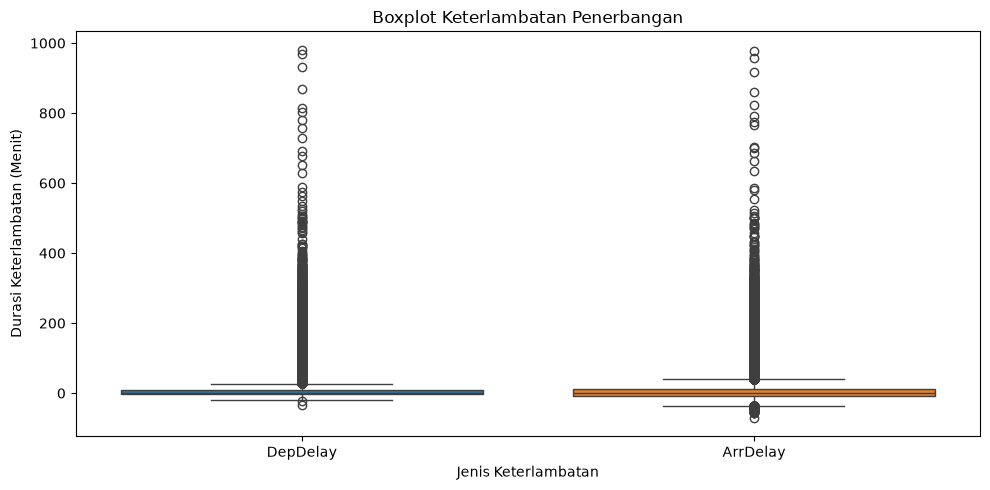

In [27]:
# Memilih kolom keterlambatan penerbangan
delay_columns = ['DepDelay', 'ArrDelay']

# Menampilkan statistik deskriptif
display(df_clean[delay_columns].describe().T)

# Membuat visualisasi boxplot
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_clean[delay_columns])

# Memberikan judul grafik
plt.title('Boxplot Keterlambatan Penerbangan')

# Memberikan label sumbu
plt.xlabel('Jenis Keterlambatan')
plt.ylabel('Durasi Keterlambatan (Menit)')

# Mengatur tata letak
plt.tight_layout()

# Menampilkan grafik
plt.show()

### Kesimpulan Pemeriksaan Outlier Keterlambatan

Berdasarkan statistik deskriptif dan visualisasi boxplot, kolom DepDelay dan ArrDelay menunjukkan adanya sejumlah nilai ekstrem. Nilai maksimum keterlambatan keberangkatan mencapai 981 menit, sedangkan keterlambatan kedatangan mencapai 978 menit.

Hasil visualisasi menunjukkan banyak titik berada di luar whisker boxplot, terutama pada nilai keterlambatan positif. Hal ini mengindikasikan adanya penerbangan dengan keterlambatan yang jauh lebih tinggi dibandingkan sebagian besar penerbangan lainnya.

Untuk mengidentifikasi kandidat outlier secara statistik, digunakan metode Interquartile Range (IQR) dengan batas 1,5 kali IQR. Namun, nilai yang teridentifikasi sebagai outlier tidak langsung dihapus karena keterlambatan ekstrem dapat mencerminkan kejadian operasional yang sebenarnya.

Oleh karena itu, diperlukan pemeriksaan lebih lanjut sebelum menentukan tindakan terhadap nilai-nilai tersebut.

In [28]:
# Menentukan kolom yang akan diperiksa
delay_columns = ['DepDelay', 'ArrDelay']

# Membuat dictionary untuk menyimpan hasil IQR
iqr_results = {}

# Menghitung batas IQR setiap kolom
for column in delay_columns:

    # Menghitung kuartil pertama dan ketiga
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    # Menghitung Interquartile Range
    IQR = Q3 - Q1

    # Menghitung batas bawah dan batas atas
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    # Menyimpan hasil perhitungan
    iqr_results[column] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound
    }

# Mengubah hasil menjadi DataFrame
iqr_table = pd.DataFrame(iqr_results).T

# Menampilkan hasil
display(iqr_table)

,Q1,Q3,IQR,Lower Bound,Upper Bound
DepDelay,-3.0,9.0,12.0,-21.0,27.0
ArrDelay,-8.0,11.0,19.0,-36.5,39.5


In [29]:
# Membuat dictionary untuk menyimpan jumlah outlier
outlier_counts = {}

# Menghitung jumlah kandidat outlier setiap kolom
for column in delay_columns:

    # Mengambil batas IQR
    lower_bound = iqr_results[column]['Lower Bound']
    upper_bound = iqr_results[column]['Upper Bound']

    # Menghitung nilai yang berada di luar batas IQR
    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    # Menyimpan jumlah outlier dan persentasenya
    outlier_counts[column] = {
        'Total Outlier': len(outliers),
        'Percentage (%)': len(outliers) / df_clean[column].notna().sum() * 100
    }

# Mengubah hasil menjadi DataFrame
outlier_summary = pd.DataFrame(outlier_counts).T

# Menampilkan hasil
display(outlier_summary)

,Total Outlier,Percentage (%)
DepDelay,25185.0,11.213717
ArrDelay,17948.0,8.017010


In [30]:
# Menyiapkan dictionary untuk menyimpan hasil pemeriksaan
outlier_direction = {}

# Memeriksa outlier bawah dan atas setiap kolom
for column in delay_columns:

    # Mengambil batas IQR
    lower_bound = iqr_results[column]['Lower Bound']
    upper_bound = iqr_results[column]['Upper Bound']

    # Menghitung outlier di bawah batas bawah
    lower_outliers = (
        df_clean[column] < lower_bound
    ).sum()

    # Menghitung outlier di atas batas atas
    upper_outliers = (
        df_clean[column] > upper_bound
    ).sum()

    # Menyimpan hasil perhitungan
    outlier_direction[column] = {
        'Outlier Bawah': lower_outliers,
        'Outlier Atas': upper_outliers,
        'Total Outlier': lower_outliers + upper_outliers
    }

# Mengubah hasil menjadi DataFrame
outlier_direction_df = pd.DataFrame(
    outlier_direction
).T

# Menampilkan hasil
display(outlier_direction_df)

,Outlier Bawah,Outlier Atas,Total Outlier
DepDelay,2,25183,25185
ArrDelay,212,17736,17948


### Kesimpulan Analisis Arah Outlier

Berdasarkan pemeriksaan menggunakan metode IQR, ditemukan bahwa sebagian besar kandidat outlier pada kolom DepDelay dan ArrDelay berada di atas batas atas. Pada DepDelay terdapat 25.183 outlier atas dan 2 outlier bawah, sedangkan pada ArrDelay terdapat 17.736 outlier atas dan 212 outlier bawah.

Hasil tersebut menunjukkan bahwa kandidat outlier lebih banyak berasal dari penerbangan dengan keterlambatan tinggi dibandingkan penerbangan yang berangkat atau tiba jauh lebih awal dari jadwal.

Kandidat outlier tetap dipertahankan karena nilai ekstrem belum tentu merupakan kesalahan pencatatan dan dapat mencerminkan kondisi operasional penerbangan yang sebenarnya. Oleh karena itu, tidak dilakukan penghapusan outlier secara langsung pada tahap ini.

,count,mean,std,min,25%,50%,75%,max
AirTime,223874.0,108.142335,56.555231,11.0,58.0,107.0,141.0,549.0
ActualElapsedTime,223874.0,129.323745,59.285838,34.0,77.0,128.0,165.0,575.0
TaxiIn,224430.0,6.098855,3.961069,1.0,4.0,5.0,7.0,165.0
TaxiOut,224549.0,15.091098,7.740373,1.0,10.0,14.0,18.0,163.0


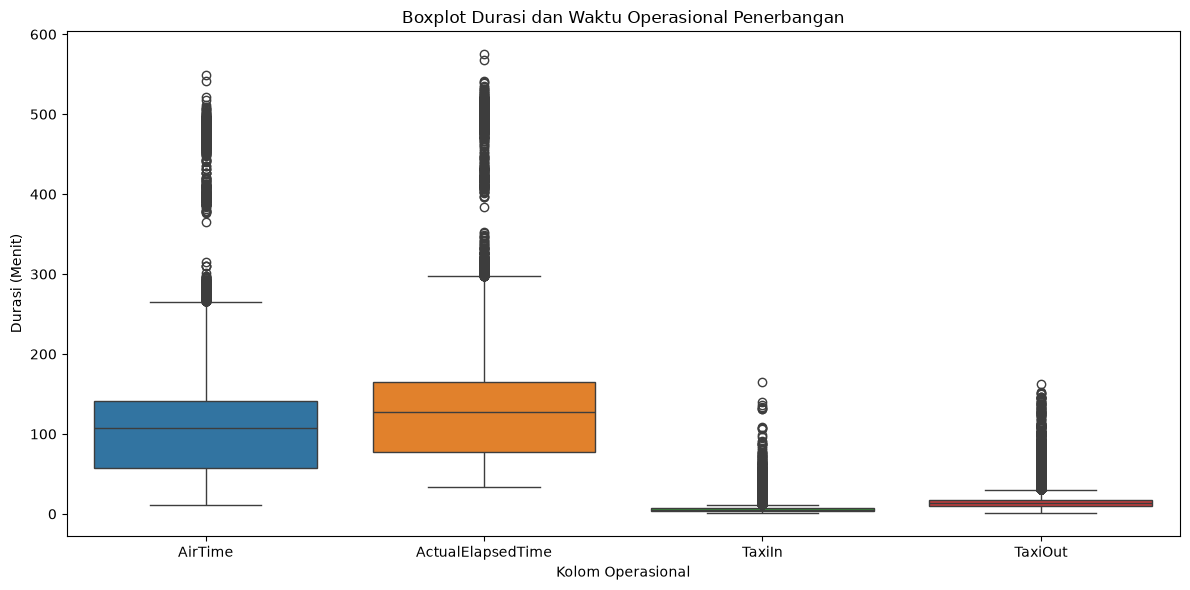

In [31]:
# Menentukan kolom durasi dan waktu operasional
duration_columns = [
    'AirTime',
    'ActualElapsedTime',
    'TaxiIn',
    'TaxiOut'
]

# Menampilkan statistik deskriptif
display(df_clean[duration_columns].describe().T)

# Membuat boxplot untuk setiap kolom
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_clean[duration_columns])

# Memberikan judul dan label
plt.title('Boxplot Durasi dan Waktu Operasional Penerbangan')
plt.xlabel('Kolom Operasional')
plt.ylabel('Durasi (Menit)')

# Mengatur tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

In [32]:
# Menyimpan hasil perhitungan IQR
duration_iqr_results = {}

# Menghitung IQR setiap kolom
for column in duration_columns:

    # Menghitung kuartil pertama dan ketiga
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    # Menghitung Interquartile Range
    IQR = Q3 - Q1

    # Menghitung batas bawah dan batas atas
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    # Menyimpan hasil perhitungan
    duration_iqr_results[column] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound
    }

# Mengubah hasil menjadi tabel
duration_iqr_table = pd.DataFrame(
    duration_iqr_results
).T

# Menampilkan tabel
display(duration_iqr_table)

,Q1,Q3,IQR,Lower Bound,Upper Bound
AirTime,58.0,141.0,83.0,-66.5,265.5
ActualElapsedTime,77.0,165.0,88.0,-55.0,297.0
TaxiIn,4.0,7.0,3.0,-0.5,11.5
TaxiOut,10.0,18.0,8.0,-2.0,30.0


### Kesimpulan Pemeriksaan Outlier Durasi dan Waktu Operasional

Berdasarkan statistik deskriptif dan visualisasi boxplot, kolom AirTime, ActualElapsedTime, TaxiIn, dan TaxiOut menunjukkan adanya nilai ekstrem. Nilai maksimum masing-masing kolom mencapai 549 menit, 575 menit, 165 menit, dan 163 menit.

Identifikasi awal menggunakan metode Interquartile Range (IQR) menunjukkan batas atas sebesar 265,5 menit untuk AirTime, 297 menit untuk ActualElapsedTime, 11,5 menit untuk TaxiIn, dan 30 menit untuk TaxiOut.

Visualisasi boxplot memperlihatkan bahwa terdapat sejumlah data yang berada di atas batas atas IQR. Meskipun demikian, nilai-nilai tersebut belum dapat dianggap sebagai kesalahan pencatatan karena mungkin mencerminkan kondisi operasional penerbangan yang sebenarnya.

Oleh karena itu, kandidat outlier akan dipertahankan sementara dan jumlahnya akan dianalisis lebih lanjut sebelum menentukan tindakan Data Cleaning.

In [33]:
# Membuat dictionary untuk menyimpan jumlah kandidat outlier
duration_outlier_counts = {}

# Menghitung kandidat outlier setiap kolom
for column in duration_columns:

    # Mengambil batas IQR
    lower_bound = duration_iqr_results[column]['Lower Bound']
    upper_bound = duration_iqr_results[column]['Upper Bound']

    # Menghitung outlier di bawah batas bawah
    lower_outliers = (
        df_clean[column] < lower_bound
    ).sum()

    # Menghitung outlier di atas batas atas
    upper_outliers = (
        df_clean[column] > upper_bound
    ).sum()

    # Menghitung total kandidat outlier
    total_outliers = lower_outliers + upper_outliers

    # Menghitung persentase kandidat outlier
    percentage = (
        total_outliers / df_clean[column].notna().sum()
    ) * 100

    # Menyimpan hasil
    duration_outlier_counts[column] = {
        'Outlier Bawah': lower_outliers,
        'Outlier Atas': upper_outliers,
        'Total Outlier': total_outliers,
        'Percentage (%)': percentage
    }

# Mengubah hasil menjadi DataFrame
duration_outlier_summary = pd.DataFrame(
    duration_outlier_counts
).T

# Menampilkan hasil
display(duration_outlier_summary)

,Outlier Bawah,Outlier Atas,Total Outlier,Percentage (%)
AirTime,0.0,1115.0,1115.0,0.498048
ActualElapsedTime,0.0,890.0,890.0,0.397545
TaxiIn,0.0,14370.0,14370.0,6.402887
TaxiOut,0.0,7910.0,7910.0,3.522616


### Kesimpulan Jumlah Kandidat Outlier Durasi dan Waktu Operasional

Berdasarkan metode Interquartile Range (IQR), ditemukan kandidat outlier pada seluruh kolom durasi dan waktu operasional penerbangan. Kolom AirTime memiliki 1.115 kandidat outlier atau 0,50%, ActualElapsedTime memiliki 890 kandidat outlier atau 0,40%, TaxiIn memiliki 14.370 kandidat outlier atau 6,40%, dan TaxiOut memiliki 7.910 kandidat outlier atau 3,52%.

Seluruh kandidat outlier berasal dari nilai di atas batas atas IQR, sedangkan tidak ditemukan nilai di bawah batas bawah. Persentase kandidat outlier tertinggi terdapat pada kolom TaxiIn, yang menunjukkan adanya sejumlah penerbangan dengan waktu operasional di darat lebih panjang dibandingkan mayoritas penerbangan lainnya.

Kandidat outlier tidak langsung dihapus karena nilai ekstrem tersebut masih mungkin mencerminkan kondisi operasional penerbangan yang sebenarnya. Oleh karena itu, seluruh nilai dipertahankan sementara untuk menjaga informasi dalam dataset.

In [34]:
# Memeriksa konsistensi durasi penerbangan
duration_invalid = df_clean[
    (df_clean['ActualElapsedTime'] < df_clean['AirTime'])
]

# Memeriksa penerbangan yang sekaligus dibatalkan dan dialihkan
status_invalid = df_clean[
    (df_clean['Cancelled'] == 1) &
    (df_clean['Diverted'] == 1)
]

# Memeriksa penerbangan batal yang memiliki durasi aktual
cancelled_with_duration = df_clean[
    (df_clean['Cancelled'] == 1) &
    (
        df_clean['ActualElapsedTime'].notna() |
        df_clean['AirTime'].notna()
    )
]

# Menampilkan hasil pemeriksaan
print("Durasi aktual lebih pendek daripada AirTime:",
      len(duration_invalid))

print("Penerbangan sekaligus batal dan dialihkan:",
      len(status_invalid))

print("Penerbangan batal dengan durasi aktual:",
      len(cancelled_with_duration))

Durasi aktual lebih pendek daripada AirTime: 0
Penerbangan sekaligus batal dan dialihkan: 0
Penerbangan batal dengan durasi aktual: 0


### Kesimpulan Pemeriksaan Konsistensi Data

Berdasarkan pemeriksaan konsistensi data, tidak ditemukan pelanggaran pada ketiga aturan yang diuji. Pertama, tidak terdapat penerbangan dengan ActualElapsedTime lebih pendek daripada AirTime. Kedua, tidak ditemukan penerbangan yang memiliki status Cancelled dan Diverted secara bersamaan. Ketiga, tidak terdapat penerbangan yang dibatalkan tetapi masih memiliki nilai ActualElapsedTime atau AirTime.

Hasil tersebut menunjukkan bahwa dataset memenuhi ketiga aturan konsistensi yang diperiksa. Oleh karena itu, tidak diperlukan perubahan data berdasarkan ketiga pemeriksaan tersebut.

In [35]:
# Fungsi untuk mengubah format HHMM menjadi total menit
def hhmm_to_minutes(time):
    if pd.isna(time):
        return np.nan

    # Memisahkan jam dan menit
    hour = int(time) // 100
    minute = int(time) % 100

    # Mengubah menjadi total menit
    return hour * 60 + minute


# Membuat kolom waktu keberangkatan dalam menit
df_clean['DepTime_Minutes'] = df_clean['DepTime'].apply(
    hhmm_to_minutes
)

# Membuat kolom waktu kedatangan dalam menit
df_clean['ArrTime_Minutes'] = df_clean['ArrTime'].apply(
    hhmm_to_minutes
)

# Menampilkan beberapa hasil konversi
display(
    df_clean[
        ['DepTime', 'DepTime_Minutes', 'ArrTime', 'ArrTime_Minutes']
    ].head()
)

,DepTime,DepTime_Minutes,ArrTime,ArrTime_Minutes
0,1400.0,840.0,1500.0,900.0
1,1401.0,841.0,1501.0,901.0
2,1352.0,832.0,1502.0,902.0
3,1403.0,843.0,1513.0,913.0
4,1405.0,845.0,1507.0,907.0


In [36]:
# Menghitung selisih waktu kedatangan dan keberangkatan
df_clean['TimeDifference'] = (
    df_clean['ArrTime_Minutes'] -
    df_clean['DepTime_Minutes']
)

# Menampilkan statistik selisih waktu
display(df_clean['TimeDifference'].describe())

count    224430.000000
mean        109.630860
std         165.589768
min       -1402.000000
25%          67.000000
50%         100.000000
75%         186.000000
max         830.000000
Name: TimeDifference, dtype: float64

In [37]:
# Mengelompokkan hasil selisih waktu berdasarkan tanda
time_difference_summary = pd.DataFrame({
    'Kategori': [
        'Negatif',
        'Nol',
        'Positif'
    ],
    'Jumlah': [
        (df_clean['TimeDifference'] < 0).sum(),
        (df_clean['TimeDifference'] == 0).sum(),
        (df_clean['TimeDifference'] > 0).sum()
    ]
})

# Menghitung persentase setiap kategori
time_difference_summary['Percentage (%)'] = (
    time_difference_summary['Jumlah'] /
    df_clean['TimeDifference'].notna().sum() * 100
)

# Menampilkan hasil
display(time_difference_summary)

,Kategori,Jumlah,Percentage (%)
0,Negatif,2718,1.211068
1,Nol,0,0.000000
2,Positif,221712,98.788932


In [38]:
# Menentukan aturan validasi setiap kolom
validation_rules = {
    'Distance': lambda x: x <= 0,
    'AirTime': lambda x: x <= 0,
    'ActualElapsedTime': lambda x: x <= 0,
    'TaxiIn': lambda x: x < 0,
    'TaxiOut': lambda x: x < 0,
    'Month': lambda x: ~x.between(1, 12),
    'DayOfWeek': lambda x: ~x.between(1, 7),
    'DayofMonth': lambda x: ~x.between(1, 31)
}

# Menyimpan hasil pemeriksaan
invalid_summary = {}

# Memeriksa setiap kolom berdasarkan aturan
for column, rule in validation_rules.items():

    # Menghitung jumlah nilai tidak valid
    invalid_count = rule(df_clean[column]).sum()

    # Menyimpan hasil
    invalid_summary[column] = invalid_count

# Mengubah hasil menjadi DataFrame
invalid_table = pd.DataFrame(
    list(invalid_summary.items()),
    columns=['Column', 'Invalid Values']
)

# Menampilkan hasil
display(invalid_table)

,Column,Invalid Values
0,Distance,0
1,AirTime,0
2,ActualElapsedTime,0
3,TaxiIn,0
4,TaxiOut,0
5,Month,0
6,DayOfWeek,0
7,DayofMonth,0


In [39]:
# Memeriksa jumlah baris duplikat
duplicate_count = df_clean.duplicated().sum()

# Memeriksa jumlah ID penerbangan yang duplikat
duplicate_flight = df_clean.duplicated(
    subset=['Year', 'Month', 'DayofMonth',
            'UniqueCarrier', 'FlightNum', 'Origin']
).sum()

# Menampilkan ukuran dataset
print("Ukuran dataset:", df_clean.shape)

# Menampilkan jumlah duplikasi seluruh baris
print("Duplikasi seluruh baris:", duplicate_count)

# Menampilkan jumlah kombinasi identitas penerbangan yang duplikat
print("Duplikasi kombinasi identitas penerbangan:", duplicate_flight)

# Menampilkan seluruh nama kolom
print("\nDaftar kolom:")
print(df_clean.columns.tolist())

Ukuran dataset: (227496, 24)
Duplikasi seluruh baris: 0
Duplikasi kombinasi identitas penerbangan: 0

Daftar kolom:
['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'DepTime', 'ArrTime', 'UniqueCarrier', 'FlightNum', 'TailNum', 'ActualElapsedTime', 'AirTime', 'ArrDelay', 'DepDelay', 'Origin', 'Dest', 'Distance', 'TaxiIn', 'TaxiOut', 'Cancelled', 'CancellationCode', 'Diverted', 'DepTime_Minutes', 'ArrTime_Minutes', 'TimeDifference']


In [40]:
# Menentukan kolom bantu yang tidak diperlukan dalam dataset akhir
helper_columns = [
    'DepTime_Minutes',
    'ArrTime_Minutes',
    'TimeDifference'
]

# Menghapus kolom bantu dari dataset cleaning
df_clean = df_clean.drop(columns=helper_columns)

# Memeriksa ukuran dataset setelah penghapusan
print("Ukuran dataset setelah penghapusan:", df_clean.shape)

# Memeriksa kembali daftar kolom
print("\nDaftar kolom:")
print(df_clean.columns.tolist())

Ukuran dataset setelah penghapusan: (227496, 21)

Daftar kolom:
['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'DepTime', 'ArrTime', 'UniqueCarrier', 'FlightNum', 'TailNum', 'ActualElapsedTime', 'AirTime', 'ArrDelay', 'DepDelay', 'Origin', 'Dest', 'Distance', 'TaxiIn', 'TaxiOut', 'Cancelled', 'CancellationCode', 'Diverted']


In [41]:
# Memeriksa ukuran dataset setelah proses cleaning
print("Ukuran dataset asli:", df.shape)
print("Ukuran dataset setelah cleaning:", df_clean.shape)

# Menampilkan informasi struktur dataset
print("\nInformasi dataset setelah cleaning:")
df_clean.info()

Ukuran dataset asli: (227496, 21)
Ukuran dataset setelah cleaning: (227496, 21)

Informasi dataset setelah cleaning:
<class 'pandas.DataFrame'>
RangeIndex: 227496 entries, 0 to 227495
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Year               227496 non-null  int64  
 1   Month              227496 non-null  int64  
 2   DayofMonth         227496 non-null  int64  
 3   DayOfWeek          227496 non-null  int64  
 4   DepTime            224591 non-null  float64
 5   ArrTime            224430 non-null  float64
 6   UniqueCarrier      227496 non-null  str    
 7   FlightNum          227496 non-null  int64  
 8   TailNum            226701 non-null  str    
 9   ActualElapsedTime  223874 non-null  float64
 10  AirTime            223874 non-null  float64
 11  ArrDelay           223874 non-null  float64
 12  DepDelay           224591 non-null  float64
 13  Origin             227496 non-null  str    

In [42]:
# Menghitung jumlah missing values pada setiap kolom
missing_values = df_clean.isnull().sum()

# Menghitung persentase missing values
missing_percentage = (missing_values / len(df_clean)) * 100

# Membuat tabel ringkasan missing values
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Persentase (%)': missing_percentage
})

# Menampilkan hanya kolom yang masih memiliki missing values
print("Kolom dengan missing values:")
display(missing_summary[missing_summary['Missing Values'] > 0])

Kolom dengan missing values:


,Missing Values,Persentase (%)
DepTime,2905,1.276946
ArrTime,3066,1.347716
TailNum,795,0.349457
ActualElapsedTime,3622,1.592116
AirTime,3622,1.592116
ArrDelay,3622,1.592116
DepDelay,2905,1.276946
TaxiIn,3066,1.347716
TaxiOut,2947,1.295407
CancellationCode,224523,98.693164


In [43]:
# Menghitung jumlah baris yang terduplikasi
duplicate_count = df_clean.duplicated().sum()

# Menampilkan hasil pemeriksaan
print("Jumlah duplikasi:", duplicate_count)

Jumlah duplikasi: 0


In [44]:
# Membandingkan jumlah baris dan kolom sebelum dan sesudah cleaning
comparison = pd.DataFrame({
    'Dataset': ['Data Asli', 'Data Setelah Cleaning'],
    'Jumlah Baris': [len(df), len(df_clean)],
    'Jumlah Kolom': [len(df.columns), len(df_clean.columns)]
})

# Menampilkan tabel perbandingan
display(comparison)

,Dataset,Jumlah Baris,Jumlah Kolom
0,Data Asli,227496,21
1,Data Setelah Cleaning,227496,21


### Keputusan Imputasi Missing Values

In [45]:
# Menentukan kolom yang akan diperiksa missing values-nya
missing_columns = [
    'DepTime', 'ArrTime', 'TailNum',
    'ActualElapsedTime', 'AirTime', 'ArrDelay',
    'DepDelay', 'TaxiIn', 'TaxiOut',
    'CancellationCode'
]

# Mengelompokkan data berdasarkan status pembatalan dan pengalihan
missing_by_status = df_clean.groupby(
    ['Cancelled', 'Diverted']
)[missing_columns].apply(
    lambda group: group.isna().sum()
)

# Menampilkan jumlah missing values setiap kelompok
display(missing_by_status)

DepTime  ArrTime  TailNum  ActualElapsedTime  AirTime  \
Cancelled Diverted                                                          
0         0               0        0        0                  0        0   
          1               0       93        0                649      649   
1         0            2905     2973      795               2973     2973   

                    ArrDelay  DepDelay  TaxiIn  TaxiOut  CancellationCode  
Cancelled Diverted                                                         
0         0                0         0       0        0            223874  
          1              649         0      93        0               649  
1         0             2973      2905    2973     2947                 0

In [46]:
# Menghitung total missing values setiap kolom
missing_summary = df_clean.isna().sum()

# Mengambil hanya kolom yang memiliki missing values
missing_summary = missing_summary[missing_summary > 0]

# Menampilkan keputusan penanganan missing values
imputation_strategy = pd.DataFrame({
    'Kolom': missing_summary.index,
    'Jumlah Missing': missing_summary.values,
    'Strategi': 'Dipertahankan (tidak diimputasi)'
})

# Menampilkan strategi penanganan
display(imputation_strategy)

,Kolom,Jumlah Missing,Strategi
0,DepTime,2905,Dipertahankan (tidak diimputasi)
1,ArrTime,3066,Dipertahankan (tidak diimputasi)
2,TailNum,795,Dipertahankan (tidak diimputasi)
3,ActualElapsedTime,3622,Dipertahankan (tidak diimputasi)
4,AirTime,3622,Dipertahankan (tidak diimputasi)
5,ArrDelay,3622,Dipertahankan (tidak diimputasi)
6,DepDelay,2905,Dipertahankan (tidak diimputasi)
7,TaxiIn,3066,Dipertahankan (tidak diimputasi)
8,TaxiOut,2947,Dipertahankan (tidak diimputasi)
9,CancellationCode,224523,Dipertahankan (tidak diimputasi)


In [47]:
# Menghitung jumlah missing values sebelum keputusan imputation
missing_before = df_clean.isna().sum().sum()

# Tidak melakukan pengisian missing values
# karena nilai yang hilang memiliki konteks operasional

# Menghitung kembali jumlah missing values
missing_after = df_clean.isna().sum().sum()

# Menampilkan perbandingan
print("Missing values sebelum:", missing_before)
print("Missing values sesudah:", missing_after)
print("Jumlah nilai yang diimputasi:", missing_before - missing_after)

Missing values sebelum: 251073
Missing values sesudah: 251073
Jumlah nilai yang diimputasi: 0


Berdasarkan hasil pemeriksaan, missing values pada dataset sebagian besar berkaitan dengan penerbangan yang dibatalkan, dialihkan, atau kolom yang tidak berlaku. Oleh karena itu, proses imputasi tidak dilakukan untuk menghindari pengisian nilai yang tidak sesuai dengan kondisi operasional. Jumlah missing values tetap sebanyak 251.073 sebelum dan sesudah proses, sehingga seluruh nilai kosong dipertahankan.

## Kesimpulan Step 3

Proses Data Cleaning dilakukan untuk memeriksa dan memastikan kualitas dataset penerbangan. Pemeriksaan mencakup missing values, outlier, konsistensi data, validitas nilai, serta duplikasi. Missing values tidak dihapus maupun diimputasi secara sembarangan karena sebagian besar berkaitan dengan kondisi operasional penerbangan, seperti pembatalan dan pengalihan penerbangan. Outlier juga dipertahankan karena belum terbukti sebagai kesalahan pencatatan. Hasil validasi akhir menunjukkan bahwa dataset tetap memiliki 227.496 baris dan 21 kolom, tanpa ditemukan duplikasi. Dengan demikian, dataset telah melalui proses pemeriksaan dan pembersihan, serta siap digunakan untuk tahap Data Analysis dengan tetap memperhatikan missing values yang ada.



## Step 4 — Data Analysis

In [48]:
# Menghitung jumlah penerbangan berdasarkan maskapai
flight_by_carrier = df_clean['UniqueCarrier'].value_counts()

# Mengubah hasil menjadi DataFrame agar lebih mudah dibaca
carrier_summary = flight_by_carrier.reset_index()

# Memberikan nama kolom
carrier_summary.columns = ['Maskapai', 'Jumlah Penerbangan']

# Menampilkan 15 maskapai berdasarkan jumlah penerbangan
display(carrier_summary)

,Maskapai,Jumlah Penerbangan
0,XE,73053
1,CO,70032
2,WN,45343
3,OO,16061
4,MQ,4648
5,US,4082
6,AA,3244
7,DL,2641
8,EV,2204
9,FL,2139


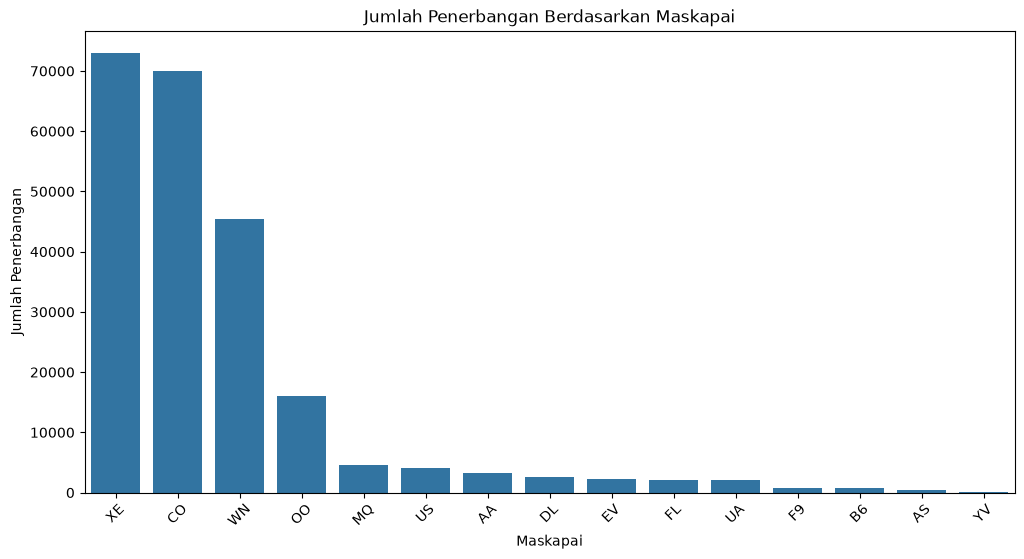

In [49]:
# Mengimpor library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur ukuran grafik
plt.figure(figsize=(12, 6))

# Membuat grafik batang jumlah penerbangan setiap maskapai
sns.barplot(
    data=carrier_summary,
    x='Maskapai',
    y='Jumlah Penerbangan'
)

# Memberikan judul dan label
plt.title('Jumlah Penerbangan Berdasarkan Maskapai')
plt.xlabel('Maskapai')
plt.ylabel('Jumlah Penerbangan')

# Memutar label sumbu X agar mudah dibaca
plt.xticks(rotation=45)

# Menampilkan grafik
plt.show()

In [50]:
# Mengambil maskapai dengan jumlah penerbangan terbanyak
most_flights = carrier_summary.iloc[0]

# Mengambil maskapai dengan jumlah penerbangan paling sedikit
least_flights = carrier_summary.iloc[-1]

# Menampilkan hasil analisis
print("Maskapai dengan penerbangan terbanyak:")
print(most_flights)

print("\nMaskapai dengan penerbangan paling sedikit:")
print(least_flights)

Maskapai dengan penerbangan terbanyak:
Maskapai                 XE
Jumlah Penerbangan    73053
Name: 0, dtype: object

Maskapai dengan penerbangan paling sedikit:
Maskapai              YV
Jumlah Penerbangan    79
Name: 14, dtype: object


Berdasarkan hasil analisis distribusi penerbangan, diketahui bahwa maskapai XE memiliki jumlah penerbangan terbanyak dengan total 73.053 penerbangan, diikuti oleh CO sebanyak 70.032 penerbangan dan WN sebanyak 45.343 penerbangan. Sementara itu, maskapai YV memiliki jumlah penerbangan paling sedikit, yaitu 79 penerbangan. Hasil visualisasi menunjukkan bahwa distribusi penerbangan antar-maskapai tidak merata, karena sebagian besar aktivitas penerbangan didominasi oleh beberapa maskapai utama.

In [51]:
# Menghitung jumlah penerbangan berdasarkan bulan
flight_by_month = df_clean['Month'].value_counts().sort_index()

# Mengubah hasil menjadi DataFrame
month_summary = flight_by_month.reset_index()

# Memberikan nama kolom
month_summary.columns = ['Bulan', 'Jumlah Penerbangan']

# Menampilkan hasil distribusi penerbangan
display(month_summary)

,Bulan,Jumlah Penerbangan
0,1,18910
1,2,17128
2,3,19470
3,4,18593
4,5,19172
5,6,19600
6,7,20548
7,8,20176
8,9,18065
9,10,18696


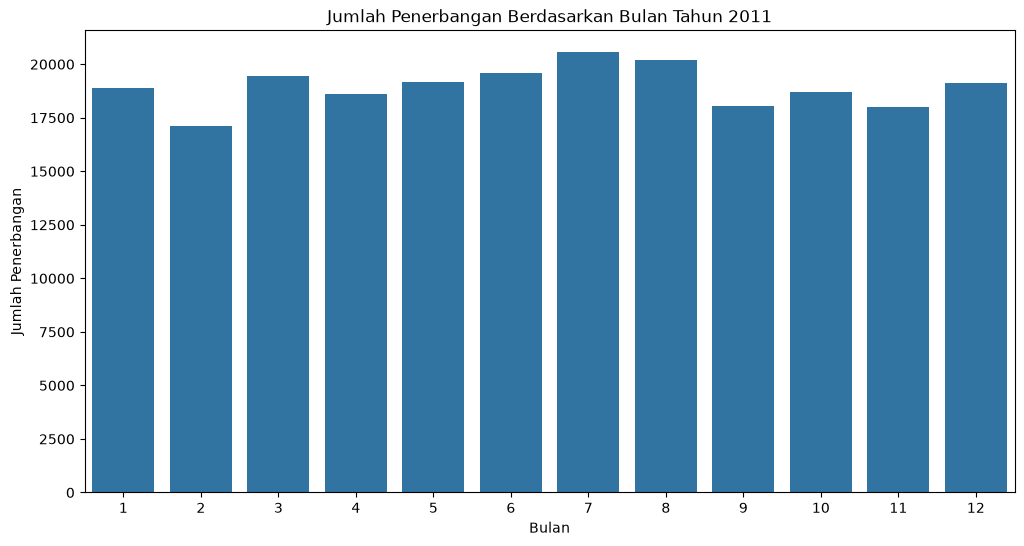

In [52]:
# Mengatur ukuran grafik
plt.figure(figsize=(12, 6))

# Membuat grafik batang jumlah penerbangan setiap bulan
sns.barplot(
    data=month_summary,
    x='Bulan',
    y='Jumlah Penerbangan'
)

# Memberikan judul dan label grafik
plt.title('Jumlah Penerbangan Berdasarkan Bulan Tahun 2011')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Penerbangan')

# Menampilkan grafik
plt.show()

In [53]:
# Mengambil bulan dengan jumlah penerbangan terbanyak
busiest_month = month_summary.loc[month_summary['Jumlah Penerbangan'].idxmax()]

# Mengambil bulan dengan jumlah penerbangan paling sedikit
quietest_month = month_summary.loc[month_summary['Jumlah Penerbangan'].idxmin()]

# Menampilkan hasil analisis
print("Bulan dengan penerbangan terbanyak:")
print(busiest_month)

print("\nBulan dengan penerbangan paling sedikit:")
print(quietest_month)

Bulan dengan penerbangan terbanyak:
Bulan                     7
Jumlah Penerbangan    20548
Name: 6, dtype: int64

Bulan dengan penerbangan paling sedikit:
Bulan                     2
Jumlah Penerbangan    17128
Name: 1, dtype: int64


Berdasarkan analisis distribusi penerbangan berdasarkan bulan selama tahun 2011, diketahui bahwa Juli merupakan bulan dengan jumlah penerbangan tertinggi, yaitu 20.548 penerbangan. Sementara itu, Februari memiliki jumlah penerbangan terendah, yaitu 17.128 penerbangan. Secara keseluruhan, aktivitas penerbangan mengalami fluktuasi sepanjang tahun dengan kecenderungan peningkatan pada pertengahan tahun dan penurunan setelah Agustus. Hasil ini menunjukkan bahwa aktivitas penerbangan tidak tersebar secara merata setiap bulannya.

In [54]:
# Menghitung jumlah penerbangan berdasarkan hari
flight_by_day = df_clean['DayOfWeek'].value_counts().sort_index()

# Mengubah hasil menjadi DataFrame
day_summary = flight_by_day.reset_index()

# Memberikan nama kolom
day_summary.columns = ['Kode Hari', 'Jumlah Penerbangan']

# Membuat pemetaan kode hari menjadi nama hari
day_names = {
    1: 'Senin',
    2: 'Selasa',
    3: 'Rabu',
    4: 'Kamis',
    5: 'Jumat',
    6: 'Sabtu',
    7: 'Minggu'
}

# Menambahkan nama hari ke dalam tabel
day_summary['Hari'] = day_summary['Kode Hari'].map(day_names)

# Menampilkan hasil analisis
display(day_summary[['Hari', 'Jumlah Penerbangan']])

,Hari,Jumlah Penerbangan
0,Senin,34360
1,Selasa,31649
2,Rabu,31926
3,Kamis,34902
4,Jumat,34972
5,Sabtu,27629
6,Minggu,32058


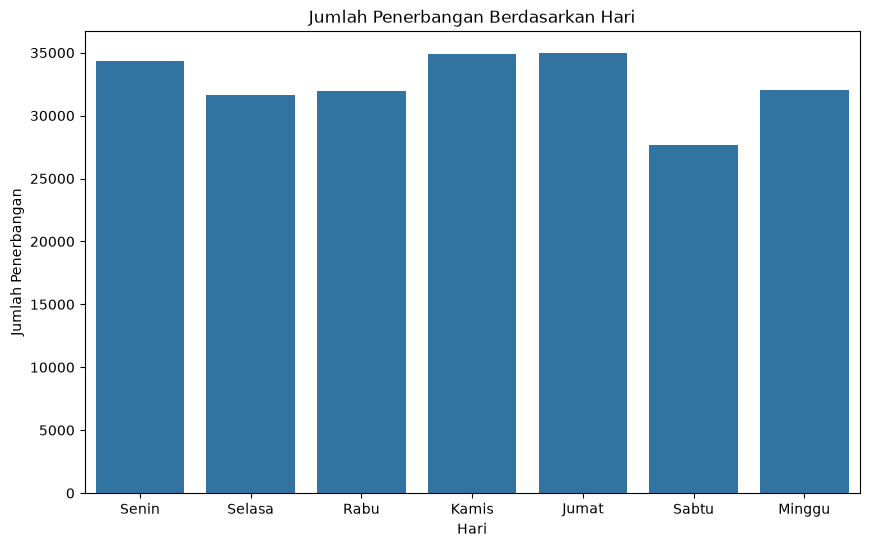

In [55]:
# Mengatur urutan nama hari
day_order = [
    'Senin', 'Selasa', 'Rabu', 'Kamis',
    'Jumat', 'Sabtu', 'Minggu'
]

# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat grafik batang jumlah penerbangan setiap hari
sns.barplot(
    data=day_summary,
    x='Hari',
    y='Jumlah Penerbangan',
    order=day_order
)

# Memberikan judul dan label grafik
plt.title('Jumlah Penerbangan Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Jumlah Penerbangan')

# Menampilkan grafik
plt.show()

In [56]:
# Mengambil hari dengan jumlah penerbangan terbanyak
busiest_day = day_summary.loc[
    day_summary['Jumlah Penerbangan'].idxmax()
]

# Mengambil hari dengan jumlah penerbangan paling sedikit
quietest_day = day_summary.loc[
    day_summary['Jumlah Penerbangan'].idxmin()
]

# Menampilkan hasil analisis
print("Hari dengan penerbangan terbanyak:")
print(busiest_day[['Hari', 'Jumlah Penerbangan']])

print("\nHari dengan penerbangan paling sedikit:")
print(quietest_day[['Hari', 'Jumlah Penerbangan']])

Hari dengan penerbangan terbanyak:
Hari                  Jumat
Jumlah Penerbangan    34972
Name: 4, dtype: object

Hari dengan penerbangan paling sedikit:
Hari                  Sabtu
Jumlah Penerbangan    27629
Name: 5, dtype: object


Berdasarkan analisis distribusi penerbangan berdasarkan hari, diketahui bahwa Jumat merupakan hari dengan jumlah penerbangan tertinggi, yaitu 34.972 penerbangan, diikuti oleh Kamis sebanyak 34.902 penerbangan dan Senin sebanyak 34.360 penerbangan. Sementara itu, Sabtu memiliki jumlah penerbangan terendah, yaitu 27.629 penerbangan. Hasil ini menunjukkan bahwa aktivitas penerbangan lebih padat pada hari kerja, terutama awal dan akhir minggu kerja, dan menurun pada hari Sabtu.

In [57]:
# Mengelompokkan penerbangan berdasarkan bandara asal dan tujuan
flight_by_route = (
    df_clean.groupby(['Origin', 'Dest'])
    .size()
    .reset_index(name='Jumlah Penerbangan')
)

# Mengurutkan rute berdasarkan jumlah penerbangan terbanyak
flight_by_route = flight_by_route.sort_values(
    by='Jumlah Penerbangan',
    ascending=False
)

# Mengambil 10 rute dengan jumlah penerbangan terbanyak
top_10_routes = flight_by_route.head(10)

# Menampilkan hasil analisis
display(top_10_routes)

,Origin,Dest,Jumlah Penerbangan
9,HOU,DAL,8243
117,IAH,ORD,5748
44,IAH,ATL,4997
59,IAH,CLT,4735
94,IAH,LAX,4668
69,IAH,DFW,4229
74,IAH,EWR,3924
122,IAH,PHX,3727
68,IAH,DEN,3645
112,IAH,MSY,3461


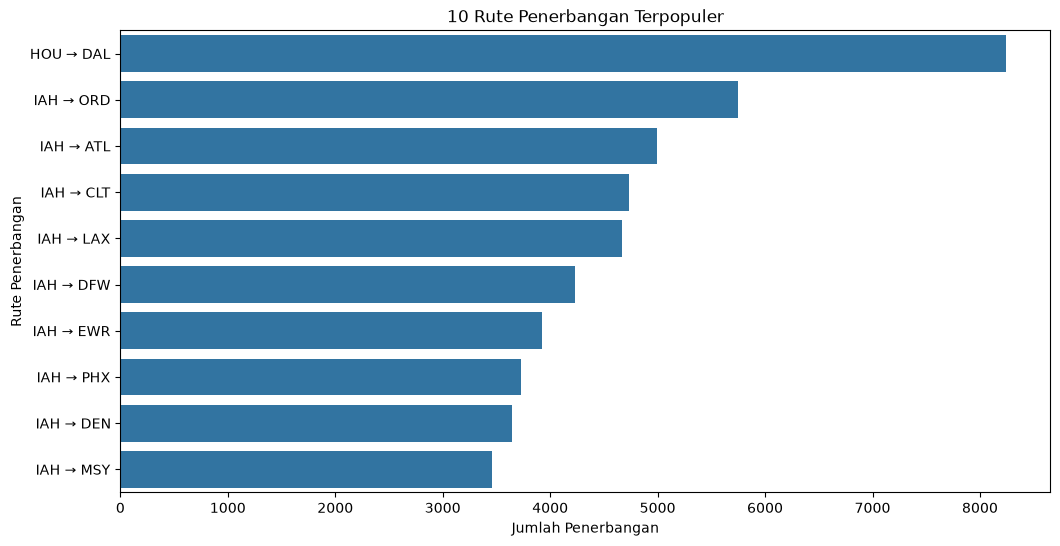

In [58]:
# Membuat kolom gabungan untuk menampilkan rute
top_10_routes = top_10_routes.copy()

# Menggabungkan bandara asal dan tujuan menjadi satu label
top_10_routes['Rute'] = (
    top_10_routes['Origin'] + ' → ' + top_10_routes['Dest']
)

# Mengatur ukuran grafik
plt.figure(figsize=(12, 6))

# Membuat grafik batang horizontal
sns.barplot(
    data=top_10_routes,
    x='Jumlah Penerbangan',
    y='Rute'
)

# Memberikan judul dan label grafik
plt.title('10 Rute Penerbangan Terpopuler')
plt.xlabel('Jumlah Penerbangan')
plt.ylabel('Rute Penerbangan')

# Menampilkan grafik
plt.show()

In [59]:
# Mengambil rute dengan jumlah penerbangan terbanyak
most_popular_route = flight_by_route.iloc[0]

# Menampilkan informasi rute terpopuler
print("Rute penerbangan paling populer:")
print("Bandara asal:", most_popular_route['Origin'])
print("Bandara tujuan:", most_popular_route['Dest'])
print("Jumlah penerbangan:", most_popular_route['Jumlah Penerbangan'])

Rute penerbangan paling populer:
Bandara asal: HOU
Bandara tujuan: DAL
Jumlah penerbangan: 8243


Berdasarkan analisis rute penerbangan, diketahui bahwa rute HOU → DAL merupakan rute dengan jumlah penerbangan terbanyak, yaitu 8.243 penerbangan. Posisi kedua ditempati oleh rute IAH → ORD dengan 5.748 penerbangan. Dari 10 rute terpopuler, sebagian besar penerbangan berasal dari bandara IAH. Hasil visualisasi menunjukkan bahwa frekuensi penerbangan terkonsentrasi pada beberapa rute tertentu, terutama HOU → DAL. Hal ini menunjukkan adanya perbedaan tingkat aktivitas penerbangan pada setiap kombinasi bandara asal dan tujuan.

In [60]:
# Mengelompokkan data berdasarkan maskapai
# Menghitung rata-rata keterlambatan keberangkatan dan kedatangan
delay_by_carrier = (
    df_clean.groupby('UniqueCarrier')
    .agg(
        Rata_rata_DepDelay=('DepDelay', 'mean'),
        Rata_rata_ArrDelay=('ArrDelay', 'mean'),
        Jumlah_Penerbangan=('UniqueCarrier', 'size')
    )
    .reset_index()
)

# Mengurutkan berdasarkan rata-rata keterlambatan kedatangan
delay_by_carrier = delay_by_carrier.sort_values(
    by='Rata_rata_ArrDelay',
    ascending=False
)

# Menampilkan hasil analisis
display(delay_by_carrier.round(2))

,UniqueCarrier,Rata_rata_DepDelay,Rata_rata_ArrDelay,Jumlah_Penerbangan
10,UA,12.92,10.46,2072
2,B6,13.32,9.86,695
9,OO,8.89,8.69,16061
13,XE,7.71,8.19,73053
6,F9,5.09,7.67,838
12,WN,13.49,7.59,45343
5,EV,12.48,7.26,2204
8,MQ,11.07,7.15,4648
3,CO,9.26,6.10,70032
4,DL,9.37,6.08,2641


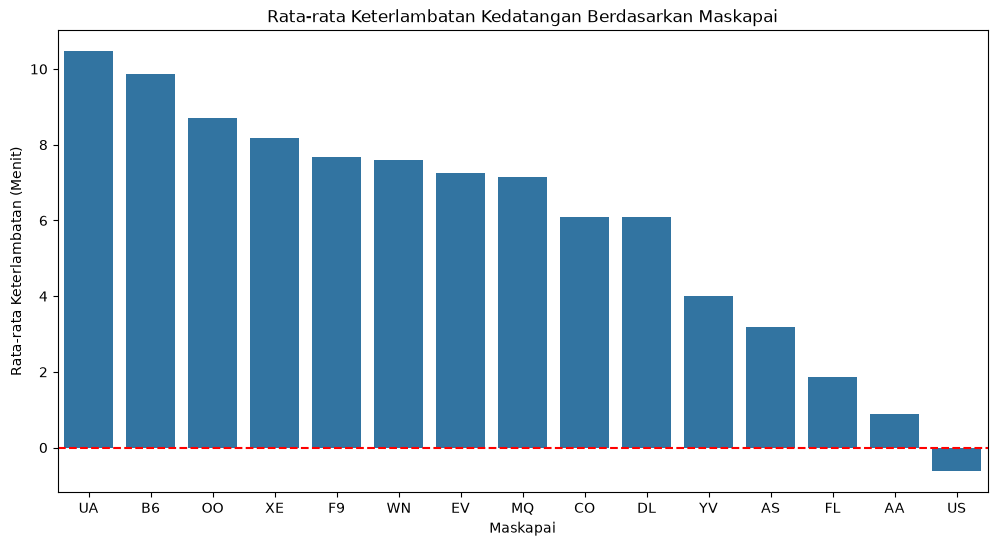

In [61]:
# Mengurutkan maskapai berdasarkan rata-rata keterlambatan kedatangan
delay_sorted = delay_by_carrier.sort_values(
    by='Rata_rata_ArrDelay',
    ascending=False
)

# Mengatur ukuran grafik
plt.figure(figsize=(12, 6))

# Membuat grafik batang rata-rata keterlambatan kedatangan
sns.barplot(
    data=delay_sorted,
    x='UniqueCarrier',
    y='Rata_rata_ArrDelay'
)

# Memberikan judul dan label grafik
plt.title('Rata-rata Keterlambatan Kedatangan Berdasarkan Maskapai')
plt.xlabel('Maskapai')
plt.ylabel('Rata-rata Keterlambatan (Menit)')

# Menambahkan garis nol sebagai batas terlambat dan lebih awal
plt.axhline(0, color='red', linestyle='--')

# Menampilkan grafik
plt.show()

In [62]:
# Mengambil maskapai dengan rata-rata keterlambatan kedatangan tertinggi
most_delayed_carrier = delay_by_carrier.loc[
    delay_by_carrier['Rata_rata_ArrDelay'].idxmax()
]

# Mengambil maskapai dengan rata-rata keterlambatan kedatangan terendah
least_delayed_carrier = delay_by_carrier.loc[
    delay_by_carrier['Rata_rata_ArrDelay'].idxmin()
]

# Menampilkan hasil analisis
print("Maskapai dengan rata-rata keterlambatan tertinggi:")
print(most_delayed_carrier)

print("\nMaskapai dengan rata-rata keterlambatan terendah:")
print(least_delayed_carrier)

Maskapai dengan rata-rata keterlambatan tertinggi:
UniqueCarrier                UA
Rata_rata_DepDelay    12.918707
Rata_rata_ArrDelay    10.462863
Jumlah_Penerbangan         2072
Name: 10, dtype: object

Maskapai dengan rata-rata keterlambatan terendah:
UniqueCarrier               US
Rata_rata_DepDelay    1.622926
Rata_rata_ArrDelay   -0.630769
Jumlah_Penerbangan        4082
Name: 11, dtype: object


Berdasarkan analisis rata-rata keterlambatan penerbangan berdasarkan maskapai, diketahui bahwa UA memiliki rata-rata keterlambatan kedatangan tertinggi sebesar 10,46 menit, diikuti oleh B6 sebesar 9,86 menit. Sementara itu, US memiliki rata-rata keterlambatan terendah sebesar -0,63 menit, yang menunjukkan bahwa penerbangan maskapai tersebut secara rata-rata tiba sedikit lebih awal dari jadwal. Hasil analisis juga menunjukkan bahwa maskapai dengan jumlah penerbangan terbanyak tidak selalu memiliki rata-rata keterlambatan tertinggi. Dengan demikian, jumlah penerbangan dan tingkat keterlambatan merupakan dua aspek operasional yang perlu dianalisis secara terpisah.

In [63]:
# Mengelompokkan data berdasarkan bulan
# Menghitung rata-rata keterlambatan kedatangan dan jumlah data yang tersedia
delay_by_month = (
    df_clean.groupby('Month')
    .agg(
        Rata_rata_ArrDelay=('ArrDelay', 'mean'),
        Jumlah_Data_Valid=('ArrDelay', 'count')
    )
    .reset_index()
)

# Membulatkan rata-rata keterlambatan menjadi dua angka desimal
delay_by_month['Rata_rata_ArrDelay'] = (
    delay_by_month['Rata_rata_ArrDelay'].round(2)
)

# Menampilkan hasil analisis
display(delay_by_month)

,Month,Rata_rata_ArrDelay,Jumlah_Data_Valid
0,1,4.93,18665
1,2,6.35,15975
2,3,7.89,19267
3,4,11.09,18266
4,5,13.13,18830
5,6,10.84,19360
6,7,9.62,20312
7,8,4.53,19927
8,9,4.24,17914
9,10,3.72,18548


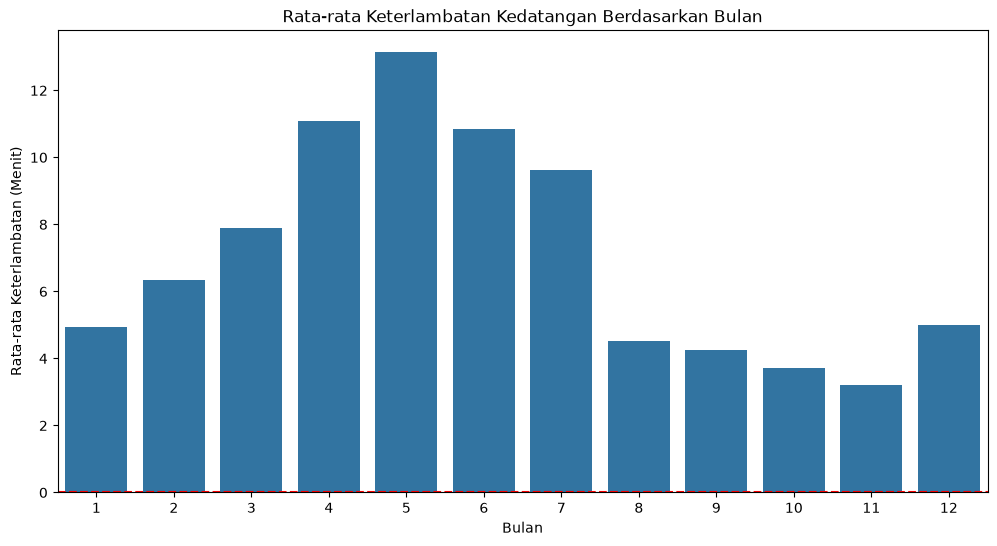

In [64]:
# Mengatur ukuran grafik
plt.figure(figsize=(12, 6))

# Membuat grafik batang rata-rata keterlambatan setiap bulan
sns.barplot(
    data=delay_by_month,
    x='Month',
    y='Rata_rata_ArrDelay'
)

# Memberikan judul dan label grafik
plt.title('Rata-rata Keterlambatan Kedatangan Berdasarkan Bulan')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata Keterlambatan (Menit)')

# Menambahkan garis nol sebagai pembatas terlambat dan lebih awal
plt.axhline(0, color='red', linestyle='--')

# Menampilkan grafik
plt.show()

In [65]:
# Mengambil bulan dengan rata-rata keterlambatan tertinggi
most_delayed_month = delay_by_month.loc[
    delay_by_month['Rata_rata_ArrDelay'].idxmax()
]

# Mengambil bulan dengan rata-rata keterlambatan terendah
least_delayed_month = delay_by_month.loc[
    delay_by_month['Rata_rata_ArrDelay'].idxmin()
]

# Menampilkan hasil analisis
print("Bulan dengan rata-rata keterlambatan tertinggi:")
print(most_delayed_month)

print("\nBulan dengan rata-rata keterlambatan terendah:")
print(least_delayed_month)

Bulan dengan rata-rata keterlambatan tertinggi:
Month                     5.00
Rata_rata_ArrDelay       13.13
Jumlah_Data_Valid     18830.00
Name: 4, dtype: float64

Bulan dengan rata-rata keterlambatan terendah:
Month                    11.00
Rata_rata_ArrDelay        3.22
Jumlah_Data_Valid     17933.00
Name: 10, dtype: float64


Berdasarkan analisis rata-rata keterlambatan kedatangan berdasarkan bulan, diketahui bahwa Mei merupakan bulan dengan rata-rata keterlambatan tertinggi, yaitu 13,13 menit. Sementara itu, November memiliki rata-rata keterlambatan terendah sebesar 3,22 menit. Hasil visualisasi menunjukkan bahwa keterlambatan meningkat dari awal tahun hingga mencapai puncak pada Mei, kemudian mengalami penurunan pada bulan-bulan berikutnya. Pada Desember, rata-rata keterlambatan kembali mengalami sedikit peningkatan. Hasil ini menunjukkan adanya variasi tingkat keterlambatan penerbangan sepanjang tahun 2011.

In [66]:
# Mengelompokkan data berdasarkan hari
# Menghitung rata-rata keterlambatan dan jumlah data yang tersedia
delay_by_day = (
    df_clean.groupby('DayOfWeek')
    .agg(
        Rata_rata_ArrDelay=('ArrDelay', 'mean'),
        Jumlah_Data_Valid=('ArrDelay', 'count')
    )
    .reset_index()
)

# Membuat pemetaan kode hari menjadi nama hari
day_names = {
    1: 'Senin',
    2: 'Selasa',
    3: 'Rabu',
    4: 'Kamis',
    5: 'Jumat',
    6: 'Sabtu',
    7: 'Minggu'
}

# Menambahkan nama hari ke tabel
delay_by_day['Hari'] = delay_by_day['DayOfWeek'].map(day_names)

# Membulatkan rata-rata keterlambatan
delay_by_day['Rata_rata_ArrDelay'] = (
    delay_by_day['Rata_rata_ArrDelay'].round(2)
)

# Menampilkan hasil analisis sesuai urutan hari
display(
    delay_by_day[
        ['Hari', 'Rata_rata_ArrDelay', 'Jumlah_Data_Valid']
    ]
)

,Hari,Rata_rata_ArrDelay,Jumlah_Data_Valid
0,Senin,8.26,33913
1,Selasa,5.55,31199
2,Rabu,5.53,31427
3,Kamis,9.80,34179
4,Jumat,7.29,34215
5,Sabtu,5.75,27279
6,Minggu,6.95,31662


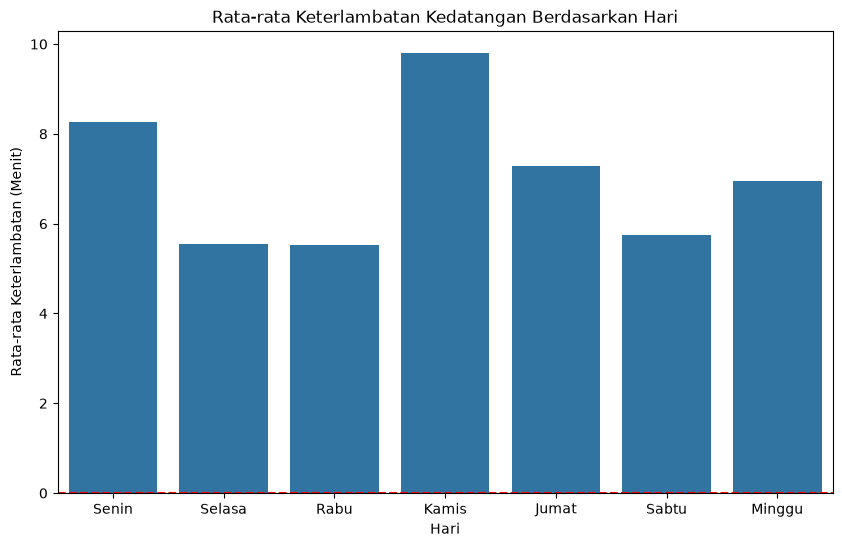

In [67]:
# Menentukan urutan hari dalam satu minggu
day_order = [
    'Senin', 'Selasa', 'Rabu', 'Kamis',
    'Jumat', 'Sabtu', 'Minggu'
]

# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat grafik batang rata-rata keterlambatan berdasarkan hari
sns.barplot(
    data=delay_by_day,
    x='Hari',
    y='Rata_rata_ArrDelay',
    order=day_order
)

# Memberikan judul dan label grafik
plt.title('Rata-rata Keterlambatan Kedatangan Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Rata-rata Keterlambatan (Menit)')

# Menambahkan garis nol sebagai batas keterlambatan
plt.axhline(0, color='red', linestyle='--')

# Menampilkan grafik
plt.show()

In [68]:
# Mengambil hari dengan rata-rata keterlambatan tertinggi
most_delayed_day = delay_by_day.loc[
    delay_by_day['Rata_rata_ArrDelay'].idxmax()
]

# Mengambil hari dengan rata-rata keterlambatan terendah
least_delayed_day = delay_by_day.loc[
    delay_by_day['Rata_rata_ArrDelay'].idxmin()
]

# Menampilkan hasil analisis
print("Hari dengan rata-rata keterlambatan tertinggi:")
print(most_delayed_day[['Hari', 'Rata_rata_ArrDelay']])

print("\nHari dengan rata-rata keterlambatan terendah:")
print(least_delayed_day[['Hari', 'Rata_rata_ArrDelay']])

Hari dengan rata-rata keterlambatan tertinggi:
Hari                  Kamis
Rata_rata_ArrDelay      9.8
Name: 3, dtype: object

Hari dengan rata-rata keterlambatan terendah:
Hari                  Rabu
Rata_rata_ArrDelay    5.53
Name: 2, dtype: object


Berdasarkan analisis rata-rata keterlambatan kedatangan berdasarkan hari, diketahui bahwa Kamis merupakan hari dengan rata-rata keterlambatan tertinggi, yaitu 9,80 menit. Sementara itu, Rabu memiliki rata-rata keterlambatan terendah sebesar 5,53 menit. Hasil visualisasi menunjukkan bahwa keterlambatan mengalami peningkatan pada hari Kamis dan kembali menurun pada Jumat. Pada akhir pekan, rata-rata keterlambatan relatif lebih rendah dibandingkan Kamis dan Senin. Hal ini menunjukkan adanya variasi keterlambatan penerbangan berdasarkan hari dalam satu minggu.

In [69]:
# Membuat salinan data yang memiliki nilai ArrDelay
delay_data = df_clean[df_clean['ArrDelay'].notna()].copy()

# Membuat fungsi untuk mengelompokkan status keterlambatan
def classify_delay(delay):
    if delay < 0:
        return 'Lebih Awal'
    elif delay == 0:
        return 'Tepat Waktu'
    else:
        return 'Terlambat'

# Membuat kolom baru untuk kategori keterlambatan
delay_data['StatusDelay'] = delay_data['ArrDelay'].apply(classify_delay)

# Menghitung jumlah penerbangan berdasarkan status keterlambatan
delay_distribution = delay_data['StatusDelay'].value_counts()

# Mengubah hasil menjadi DataFrame
delay_summary = delay_distribution.reset_index()

# Memberikan nama kolom
delay_summary.columns = ['Status Penerbangan', 'Jumlah Penerbangan']

# Menghitung persentase setiap kategori
delay_summary['Persentase (%)'] = (
    delay_summary['Jumlah Penerbangan'] /
    delay_summary['Jumlah Penerbangan'].sum() * 100
)

# Menampilkan hasil analisis
display(delay_summary.round(2))

,Status Penerbangan,Jumlah Penerbangan,Persentase (%)
0,Lebih Awal,109991,49.13
1,Terlambat,106920,47.76
2,Tepat Waktu,6963,3.11


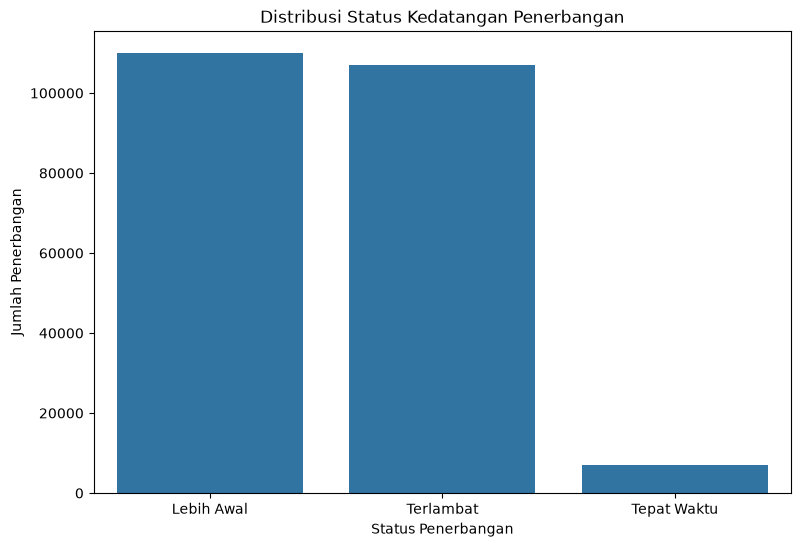

In [70]:
# Mengatur ukuran grafik
plt.figure(figsize=(9, 6))

# Membuat grafik batang distribusi status keterlambatan
sns.barplot(
    data=delay_summary,
    x='Status Penerbangan',
    y='Jumlah Penerbangan'
)

# Memberikan judul dan label grafik
plt.title('Distribusi Status Kedatangan Penerbangan')
plt.xlabel('Status Penerbangan')
plt.ylabel('Jumlah Penerbangan')

# Menampilkan grafik
plt.show()

In [71]:
# Menghitung total penerbangan dengan data ArrDelay valid
total_valid_flights = len(delay_data)

# Menghitung jumlah penerbangan yang terlambat
late_flights = (delay_data['ArrDelay'] > 0).sum()

# Menghitung jumlah penerbangan yang tiba tepat waktu
on_time_flights = (delay_data['ArrDelay'] == 0).sum()

# Menghitung jumlah penerbangan yang tiba lebih awal
early_flights = (delay_data['ArrDelay'] < 0).sum()

# Menghitung persentase masing-masing kategori
print("Total penerbangan dengan data valid:", total_valid_flights)
print("Penerbangan terlambat:", late_flights)
print("Penerbangan tepat waktu:", on_time_flights)
print("Penerbangan lebih awal:", early_flights)

print("\nPersentase keterlambatan:")
print(f"{late_flights / total_valid_flights * 100:.2f}%")

Total penerbangan dengan data valid: 223874
Penerbangan terlambat: 106920
Penerbangan tepat waktu: 6963
Penerbangan lebih awal: 109991

Persentase keterlambatan:
47.76%


Berdasarkan analisis distribusi status kedatangan penerbangan, dari total 223.874 penerbangan dengan data keterlambatan yang valid, sebanyak 109.991 penerbangan (49,13%) tiba lebih awal, 106.920 penerbangan (47,76%) mengalami keterlambatan, dan 6.963 penerbangan (3,11%) tiba tepat sesuai jadwal. Hasil visualisasi menunjukkan bahwa penerbangan yang tiba lebih awal memiliki jumlah sedikit lebih tinggi dibandingkan penerbangan yang terlambat. Sementara itu, penerbangan yang tiba tepat waktu memiliki proporsi paling rendah. Hal ini menunjukkan bahwa sebagian besar penerbangan tidak tiba tepat pada waktu yang dijadwalkan.

In [72]:
# Mengambil data yang memiliki nilai DepDelay dan ArrDelay
delay_correlation_data = df_clean[
    ['DepDelay', 'ArrDelay']
].dropna().copy()

# Menampilkan jumlah data yang digunakan
print("Jumlah data valid:", len(delay_correlation_data))

# Menampilkan lima baris pertama
display(delay_correlation_data.head())

Jumlah data valid: 223874


,DepDelay,ArrDelay
0,0.0,-10.0
1,1.0,-9.0
2,-8.0,-8.0
3,3.0,3.0
4,5.0,-3.0


In [73]:
# Menghitung korelasi Pearson antara keterlambatan keberangkatan dan kedatangan
delay_correlation = delay_correlation_data[
    'DepDelay'
].corr(delay_correlation_data['ArrDelay'])

# Menampilkan nilai korelasi
print("Korelasi DepDelay dan ArrDelay:", round(delay_correlation, 4))

Korelasi DepDelay dan ArrDelay: 0.9292


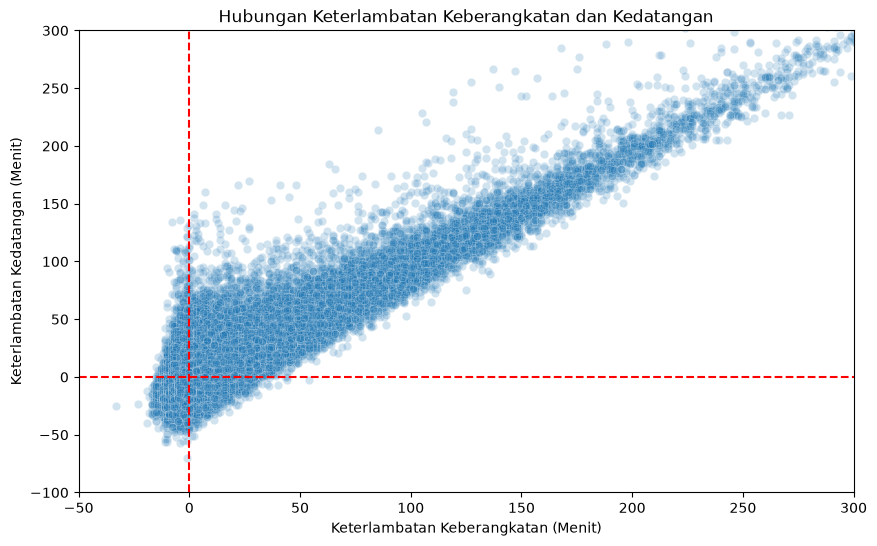

In [74]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat scatter plot hubungan keterlambatan keberangkatan dan kedatangan
sns.scatterplot(
    data=delay_correlation_data,
    x='DepDelay',
    y='ArrDelay',
    alpha=0.2
)

# Menambahkan garis nol pada kedua sumbu
plt.axhline(0, color='red', linestyle='--')
plt.axvline(0, color='red', linestyle='--')

# Memberikan judul dan label grafik
plt.title('Hubungan Keterlambatan Keberangkatan dan Kedatangan')
plt.xlabel('Keterlambatan Keberangkatan (Menit)')
plt.ylabel('Keterlambatan Kedatangan (Menit)')

# Membatasi tampilan grafik agar pola utama lebih mudah diamati
plt.xlim(-50, 300)
plt.ylim(-100, 300)

# Menampilkan grafik
plt.show()

In [75]:
# Menginterpretasikan kekuatan hubungan berdasarkan nilai korelasi
# Skala interpretasi koefisien korelasi (Sugiyono):
# 0,00-0,199 sangat lemah | 0,20-0,399 lemah | 0,40-0,599 sedang
# 0,60-0,799 kuat | 0,80-1,000 sangat kuat
r_abs = abs(delay_correlation)

if r_abs >= 0.8:
    strength = 'sangat kuat'
elif r_abs >= 0.6:
    strength = 'kuat'
elif r_abs >= 0.4:
    strength = 'sedang'
elif r_abs >= 0.2:
    strength = 'lemah'
else:
    strength = 'sangat lemah (hampir tidak ada hubungan linear)'

direction = 'positif' if delay_correlation > 0 else 'negatif'

# Menampilkan interpretasi hasil korelasi
print("Interpretasi: Korelasi", direction, strength)

Interpretasi: Korelasi positif sangat kuat


Berdasarkan analisis korelasi antara keterlambatan keberangkatan dan kedatangan, diperoleh nilai korelasi Pearson sebesar 0,9292 dengan menggunakan 223.874 data penerbangan valid. Nilai tersebut menunjukkan adanya hubungan linear positif yang sangat kuat antara kedua variabel. Hasil visualisasi scatter plot juga memperlihatkan pola peningkatan keterlambatan kedatangan seiring dengan meningkatnya keterlambatan keberangkatan. Dengan demikian, keterlambatan saat keberangkatan memiliki hubungan yang erat dengan keterlambatan saat kedatangan.

In [76]:
# Mengambil data penerbangan dengan jarak dan keterlambatan yang valid
distance_data = df_clean[
    ['Distance', 'ArrDelay']
].dropna().copy()

# Membagi jarak penerbangan menjadi empat kelompok
distance_data['Kategori_Jarak'] = pd.qcut(
    distance_data['Distance'],
    q=4,
    labels=['Pendek', 'Menengah', 'Jauh', 'Sangat Jauh']
)

# Menampilkan jumlah penerbangan dalam setiap kategori
print("Jumlah penerbangan berdasarkan kategori jarak:")
display(
    distance_data['Kategori_Jarak']
    .value_counts()
    .sort_index()
    .reset_index()
)

Jumlah penerbangan berdasarkan kategori jarak:


,Kategori_Jarak,count
0,Pendek,56238
1,Menengah,56839
2,Jauh,55552
3,Sangat Jauh,55245


In [77]:
# Mengelompokkan data berdasarkan kategori jarak
# Menghitung rata-rata keterlambatan dan jumlah penerbangan
delay_by_distance = (
    distance_data.groupby('Kategori_Jarak', observed=False)
    .agg(
        Rata_rata_ArrDelay=('ArrDelay', 'mean'),
        Jumlah_Penerbangan=('ArrDelay', 'count'),
        Rata_rata_Distance=('Distance', 'mean')
    )
    .reset_index()
)

# Membulatkan hasil rata-rata menjadi dua angka desimal
delay_by_distance = delay_by_distance.round(2)

# Menampilkan hasil analisis
display(delay_by_distance)

,Kategori_Jarak,Rata_rata_ArrDelay,Jumlah_Penerbangan,Rata_rata_Distance
0,Pendek,7.10,56238,245.92
1,Menengah,8.15,56839,612.76
2,Jauh,6.96,55552,924.90
3,Sangat Jauh,6.13,55245,1389.48


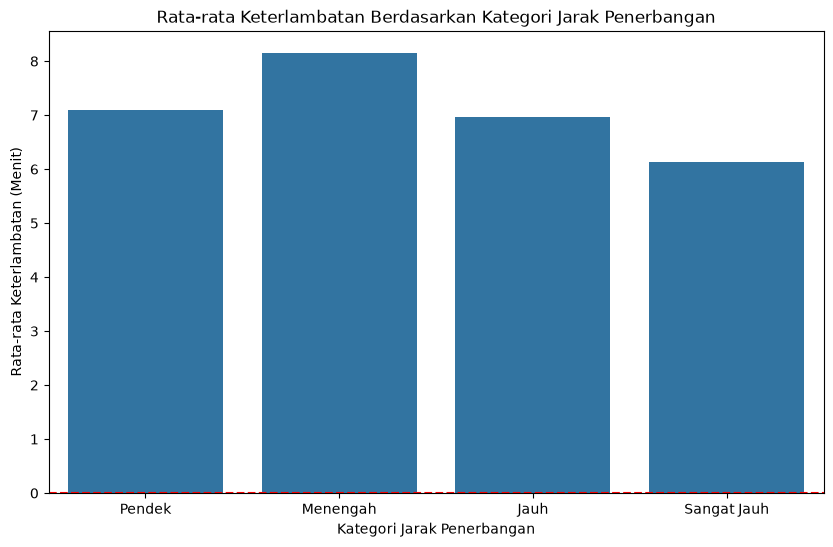

In [78]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat grafik batang rata-rata keterlambatan setiap kategori jarak
sns.barplot(
    data=delay_by_distance,
    x='Kategori_Jarak',
    y='Rata_rata_ArrDelay'
)

# Memberikan judul dan label grafik
plt.title('Rata-rata Keterlambatan Berdasarkan Kategori Jarak Penerbangan')
plt.xlabel('Kategori Jarak Penerbangan')
plt.ylabel('Rata-rata Keterlambatan (Menit)')

# Menambahkan garis nol sebagai pembatas keterlambatan
plt.axhline(0, color='red', linestyle='--')

# Menampilkan grafik
plt.show()

In [79]:
# Menghitung korelasi Pearson antara jarak dan keterlambatan kedatangan
distance_correlation = distance_data['Distance'].corr(
    distance_data['ArrDelay']
)

# Menampilkan nilai korelasi
print(
    "Korelasi Distance dan ArrDelay:",
    round(distance_correlation, 4)
)

Korelasi Distance dan ArrDelay: -0.0044


Berdasarkan analisis keterlambatan berdasarkan jarak penerbangan, diketahui bahwa kategori jarak menengah memiliki rata-rata keterlambatan tertinggi sebesar 8,15 menit, sedangkan kategori sangat jauh memiliki rata-rata keterlambatan terendah sebesar 6,13 menit. Hasil perhitungan korelasi Pearson antara jarak penerbangan dan keterlambatan kedatangan menghasilkan nilai -0,0044. Nilai tersebut menunjukkan bahwa hampir tidak terdapat hubungan linear antara kedua variabel. Dengan demikian, jarak penerbangan tidak memiliki hubungan linear yang berarti dengan tingkat keterlambatan kedatangan pada dataset ini.

In [80]:
# Mengelompokkan penerbangan berdasarkan bandara asal
# Menghitung rata-rata keterlambatan dan jumlah data valid
delay_by_origin = (
    df_clean.groupby('Origin')
    .agg(
        Rata_rata_ArrDelay=('ArrDelay', 'mean'),
        Jumlah_Data_Valid=('ArrDelay', 'count'),
        Jumlah_Penerbangan=('Origin', 'size')
    )
    .reset_index()
)

# Membulatkan rata-rata keterlambatan
delay_by_origin['Rata_rata_ArrDelay'] = (
    delay_by_origin['Rata_rata_ArrDelay'].round(2)
)

# Menampilkan hasil analisis
display(delay_by_origin)

,Origin,Rata_rata_ArrDelay,Jumlah_Data_Valid,Jumlah_Penerbangan
0,HOU,7.49,51309,52299
1,IAH,6.98,172565,175197


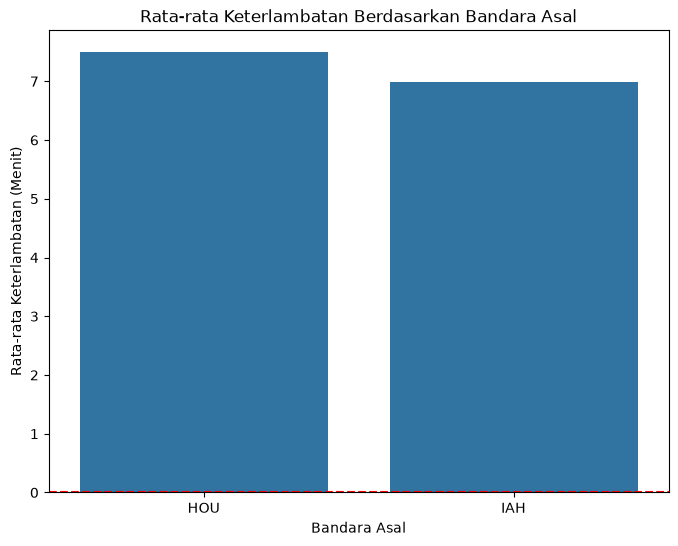

In [81]:
# Mengatur ukuran grafik
plt.figure(figsize=(8, 6))

# Membuat grafik batang rata-rata keterlambatan setiap bandara asal
sns.barplot(
    data=delay_by_origin,
    x='Origin',
    y='Rata_rata_ArrDelay'
)

# Memberikan judul dan label grafik
plt.title('Rata-rata Keterlambatan Berdasarkan Bandara Asal')
plt.xlabel('Bandara Asal')
plt.ylabel('Rata-rata Keterlambatan (Menit)')

# Menambahkan garis nol sebagai batas keterlambatan
plt.axhline(0, color='red', linestyle='--')

# Menampilkan grafik
plt.show()

In [82]:
# Mengambil bandara asal dengan rata-rata keterlambatan tertinggi
most_delayed_origin = delay_by_origin.loc[
    delay_by_origin['Rata_rata_ArrDelay'].idxmax()
]

# Mengambil bandara asal dengan rata-rata keterlambatan terendah
least_delayed_origin = delay_by_origin.loc[
    delay_by_origin['Rata_rata_ArrDelay'].idxmin()
]

# Menampilkan hasil analisis
print("Bandara asal dengan rata-rata keterlambatan tertinggi:")
print(most_delayed_origin)

print("\nBandara asal dengan rata-rata keterlambatan terendah:")
print(least_delayed_origin)

Bandara asal dengan rata-rata keterlambatan tertinggi:
Origin                  HOU
Rata_rata_ArrDelay     7.49
Jumlah_Data_Valid     51309
Jumlah_Penerbangan    52299
Name: 0, dtype: object

Bandara asal dengan rata-rata keterlambatan terendah:
Origin                   IAH
Rata_rata_ArrDelay      6.98
Jumlah_Data_Valid     172565
Jumlah_Penerbangan    175197
Name: 1, dtype: object


Berdasarkan analisis keterlambatan berdasarkan bandara asal, diketahui bahwa HOU memiliki rata-rata keterlambatan kedatangan tertinggi sebesar 7,49 menit, sedangkan IAH memiliki rata-rata sebesar 6,98 menit. Meskipun jumlah penerbangan dari IAH mencapai 175.197 penerbangan, jauh lebih banyak dibandingkan HOU yang memiliki 52.299 penerbangan, rata-rata keterlambatan IAH justru sedikit lebih rendah. Hasil ini menunjukkan bahwa tingginya jumlah penerbangan tidak selalu berbanding lurus dengan rata-rata keterlambatan pada suatu bandara.

In [83]:
# Mengambil data TaxiOut dan DepDelay yang tidak memiliki missing values
taxi_data = df_clean[
    ['TaxiOut', 'DepDelay']
].dropna().copy()

# Menampilkan jumlah data valid
print("Jumlah data valid:", len(taxi_data))

# Menampilkan lima baris pertama
display(taxi_data.head())

Jumlah data valid: 224549


,TaxiOut,DepDelay
0,13.0,0.0
1,9.0,1.0
2,17.0,-8.0
3,22.0,3.0
4,9.0,5.0


In [84]:
# Menghitung korelasi Pearson antara TaxiOut dan DepDelay
taxi_correlation = taxi_data['TaxiOut'].corr(
    taxi_data['DepDelay']
)

# Menampilkan nilai korelasi
print("Korelasi TaxiOut dan DepDelay:", round(taxi_correlation, 4))

Korelasi TaxiOut dan DepDelay: 0.002


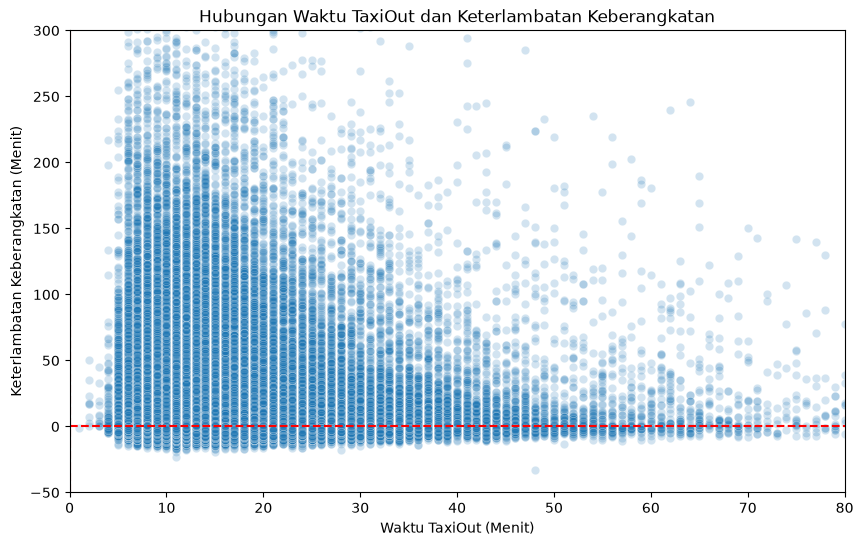

In [85]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat scatter plot hubungan TaxiOut dan DepDelay
sns.scatterplot(
    data=taxi_data,
    x='TaxiOut',
    y='DepDelay',
    alpha=0.2
)

# Menambahkan garis nol pada kedua sumbu
plt.axhline(0, color='red', linestyle='--')
plt.axvline(0, color='red', linestyle='--')

# Memberikan judul dan label grafik
plt.title('Hubungan Waktu TaxiOut dan Keterlambatan Keberangkatan')
plt.xlabel('Waktu TaxiOut (Menit)')
plt.ylabel('Keterlambatan Keberangkatan (Menit)')

# Membatasi tampilan grafik agar pola utama lebih mudah diamati
plt.xlim(0, 80)
plt.ylim(-50, 300)

# Menampilkan grafik
plt.show()

In [86]:
# Menginterpretasikan kekuatan hubungan berdasarkan nilai korelasi
# Skala interpretasi koefisien korelasi (Sugiyono):
# 0,00-0,199 sangat lemah | 0,20-0,399 lemah | 0,40-0,599 sedang
# 0,60-0,799 kuat | 0,80-1,000 sangat kuat
r_abs = abs(taxi_correlation)

if r_abs >= 0.8:
    strength = 'sangat kuat'
elif r_abs >= 0.6:
    strength = 'kuat'
elif r_abs >= 0.4:
    strength = 'sedang'
elif r_abs >= 0.2:
    strength = 'lemah'
else:
    strength = 'sangat lemah (hampir tidak ada hubungan linear)'

direction = 'positif' if taxi_correlation > 0 else 'negatif'

# Menampilkan interpretasi hasil korelasi
print("Interpretasi: Korelasi", direction, strength)

Interpretasi: Korelasi positif sangat lemah (hampir tidak ada hubungan linear)


## Kesimpulan Data Analysis

Berdasarkan analisis terhadap 227.496 data penerbangan tahun 2011, maskapai XE memiliki jumlah penerbangan terbanyak dan rute HOU → DAL menjadi rute terpopuler. Aktivitas penerbangan tertinggi terjadi pada bulan Juli dan hari Jumat.

Dari sisi keterlambatan, UA memiliki rata-rata keterlambatan tertinggi sebesar 10,46 menit. Sebanyak 47,76% penerbangan mengalami keterlambatan, sedangkan 49,13% tiba lebih awal. Korelasi antara keterlambatan keberangkatan dan kedatangan sangat kuat (0,9292), sementara jarak penerbangan dan waktu TaxiOut hampir tidak memiliki hubungan linear dengan keterlambatan.

Secara keseluruhan, keterlambatan penerbangan memiliki pola yang berbeda berdasarkan maskapai, waktu, dan bandara asal.

## EDA Q1 — Distribusi Keterlambatan Penerbangan

In [87]:
# Memilih kolom keterlambatan keberangkatan dan kedatangan
delay_columns = ['DepDelay', 'ArrDelay']

# Menghitung statistik deskriptif setiap kolom
delay_statistics = df_clean[delay_columns].describe().T

# Menampilkan statistik dengan dua angka desimal
display(delay_statistics.round(2))

,count,mean,std,min,25%,50%,75%,max
DepDelay,224591.0,9.44,28.80,-33.0,-3.0,0.0,9.0,981.0
ArrDelay,223874.0,7.09,30.71,-70.0,-8.0,0.0,11.0,978.0


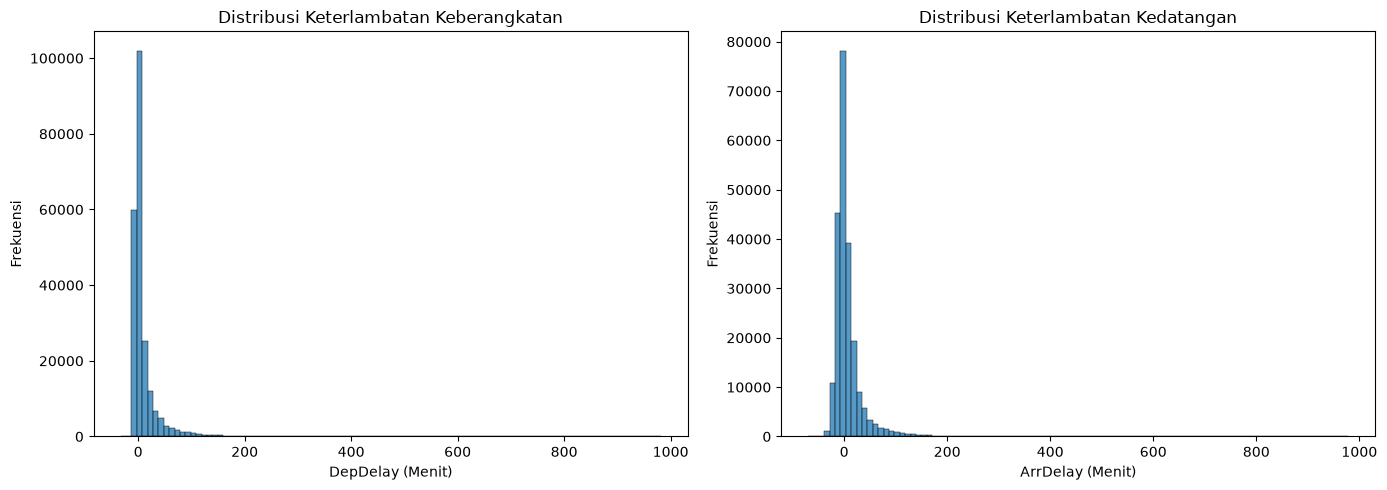

In [88]:
# Membuat area grafik dengan dua subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Membuat histogram keterlambatan keberangkatan
sns.histplot(
    data=df_clean,
    x='DepDelay',
    bins=100,
    ax=axes[0]
)

# Memberikan judul dan label grafik pertama
axes[0].set_title('Distribusi Keterlambatan Keberangkatan')
axes[0].set_xlabel('DepDelay (Menit)')
axes[0].set_ylabel('Frekuensi')

# Membuat histogram keterlambatan kedatangan
sns.histplot(
    data=df_clean,
    x='ArrDelay',
    bins=100,
    ax=axes[1]
)

# Memberikan judul dan label grafik kedua
axes[1].set_title('Distribusi Keterlambatan Kedatangan')
axes[1].set_xlabel('ArrDelay (Menit)')
axes[1].set_ylabel('Frekuensi')

# Mengatur tata letak grafik
plt.tight_layout()

# Menampilkan kedua histogram
plt.show()

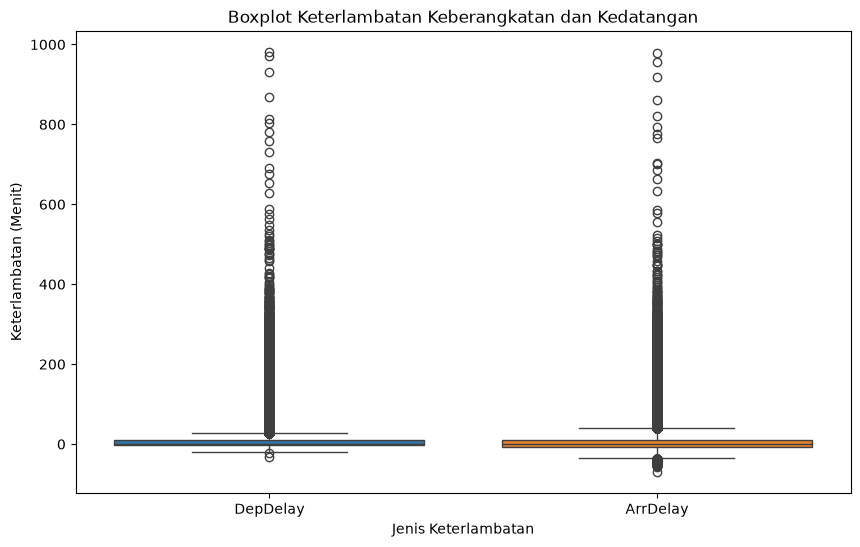

In [89]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Menggabungkan kedua variabel ke dalam boxplot
sns.boxplot(
    data=df_clean[['DepDelay', 'ArrDelay']]
)

# Memberikan judul dan label grafik
plt.title('Boxplot Keterlambatan Keberangkatan dan Kedatangan')
plt.xlabel('Jenis Keterlambatan')
plt.ylabel('Keterlambatan (Menit)')

# Menampilkan grafik
plt.show()

In [90]:
# Membuat daftar untuk menyimpan hasil perhitungan outlier
outlier_results = []

# Memeriksa outlier pada setiap variabel keterlambatan
for column in delay_columns:

    # Mengambil data yang tidak memiliki missing values
    values = df_clean[column].dropna()

    # Menghitung kuartil pertama dan ketiga
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    # Menghitung interquartile range
    IQR = Q3 - Q1

    # Menentukan batas bawah dan batas atas
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Menghitung jumlah outlier
    outlier_count = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    # Menyimpan hasil perhitungan
    outlier_results.append({
        'Variabel': column,
        'Batas Bawah': lower_bound,
        'Batas Atas': upper_bound,
        'Jumlah Outlier': outlier_count,
        'Persentase Outlier (%)': (
            outlier_count / len(values) * 100
        )
    })

# Mengubah hasil menjadi DataFrame
outlier_summary = pd.DataFrame(outlier_results)

# Menampilkan hasil perhitungan
display(outlier_summary.round(2))

,Variabel,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier (%)
0,DepDelay,-21.0,27.0,25185,11.21
1,ArrDelay,-36.5,39.5,17948,8.02


## Kesimpulan EDA Q1
Hasil analisis menunjukkan bahwa distribusi keterlambatan keberangkatan dan kedatangan cenderung miring ke kanan (right-skewed), dengan median sebesar 0 menit. Rata-rata keterlambatan keberangkatan adalah 9,44 menit dan kedatangan 7,09 menit. Ditemukan pula sejumlah outlier pada kedua variabel, yaitu 11,21% pada DepDelay dan 8,02% pada ArrDelay. Outlier tersebut dipertahankan karena dapat merepresentasikan kondisi operasional penerbangan.

## EDA Q2 — Hubungan Keterlambatan Keberangkatan dan Kedatangan

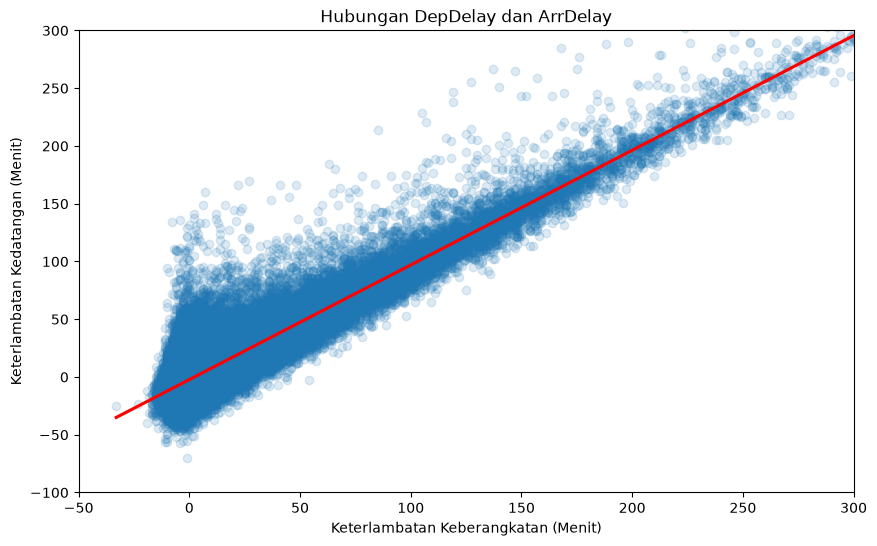

In [91]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat scatter plot dengan garis regresi
sns.regplot(
    data=delay_correlation_data,
    x='DepDelay',
    y='ArrDelay',
    scatter_kws={'alpha': 0.15},
    line_kws={'color': 'red'}
)

# Memberikan judul dan label grafik
plt.title('Hubungan DepDelay dan ArrDelay')
plt.xlabel('Keterlambatan Keberangkatan (Menit)')
plt.ylabel('Keterlambatan Kedatangan (Menit)')

# Membatasi tampilan agar pola utama lebih jelas
plt.xlim(-50, 300)
plt.ylim(-100, 300)

# Menampilkan grafik
plt.show()

In [92]:
# Menghitung korelasi Pearson untuk mengukur hubungan linear
pearson_corr = delay_correlation_data['DepDelay'].corr(
    delay_correlation_data['ArrDelay'],
    method='pearson'
)

# Menghitung korelasi Spearman berdasarkan peringkat data
spearman_corr = delay_correlation_data['DepDelay'].corr(
    delay_correlation_data['ArrDelay'],
    method='spearman'
)

# Menampilkan hasil korelasi
print("Korelasi Pearson:", round(pearson_corr, 4))
print("Korelasi Spearman:", round(spearman_corr, 4))

Korelasi Pearson: 0.9292
Korelasi Spearman: 0.6602


## Kesimpulan EDA Q2
Hasil analisis menunjukkan adanya hubungan positif antara keterlambatan keberangkatan dan kedatangan. Korelasi Pearson sebesar 0,9292 menunjukkan hubungan linear yang sangat kuat, sedangkan korelasi Spearman sebesar 0,6602 menunjukkan hubungan positif berdasarkan peringkat. Hal ini menunjukkan bahwa penerbangan yang terlambat berangkat cenderung mengalami keterlambatan saat tiba.

## EDA Q3 — Hubungan Jarak dan Durasi Penerbangan

In [93]:
# Memilih kolom jarak dan durasi penerbangan
flight_characteristics = df_clean[
    ['Distance', 'AirTime']
]

# Menghitung statistik deskriptif
flight_statistics = flight_characteristics.describe().T

# Menampilkan hasil statistik
display(flight_statistics.round(2))

,count,mean,std,min,25%,50%,75%,max
Distance,227496.0,787.78,453.68,79.0,376.0,809.0,1042.0,3904.0
AirTime,223874.0,108.14,56.56,11.0,58.0,107.0,141.0,549.0


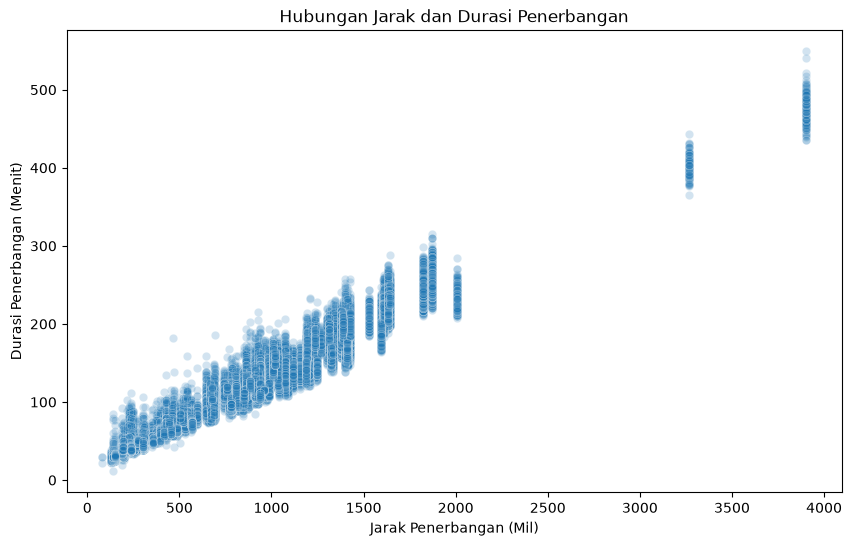

In [94]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat scatter plot hubungan jarak dan durasi penerbangan
sns.scatterplot(
    data=df_clean,
    x='Distance',
    y='AirTime',
    alpha=0.2
)

# Memberikan judul dan label grafik
plt.title('Hubungan Jarak dan Durasi Penerbangan')
plt.xlabel('Jarak Penerbangan (Mil)')
plt.ylabel('Durasi Penerbangan (Menit)')

# Menampilkan grafik
plt.show()

In [95]:
# Mengambil data yang memiliki nilai Distance dan AirTime
flight_correlation_data = df_clean[
    ['Distance', 'AirTime']
].dropna()

# Menghitung korelasi Pearson
pearson_distance_airtime = flight_correlation_data[
    'Distance'
].corr(flight_correlation_data['AirTime'], method='pearson')

# Menghitung korelasi Spearman
spearman_distance_airtime = flight_correlation_data[
    'Distance'
].corr(flight_correlation_data['AirTime'], method='spearman')

# Menampilkan hasil korelasi
print("Korelasi Pearson:", round(pearson_distance_airtime, 4))
print("Korelasi Spearman:", round(spearman_distance_airtime, 4))

Korelasi Pearson: 0.9847
Korelasi Spearman: 0.9835


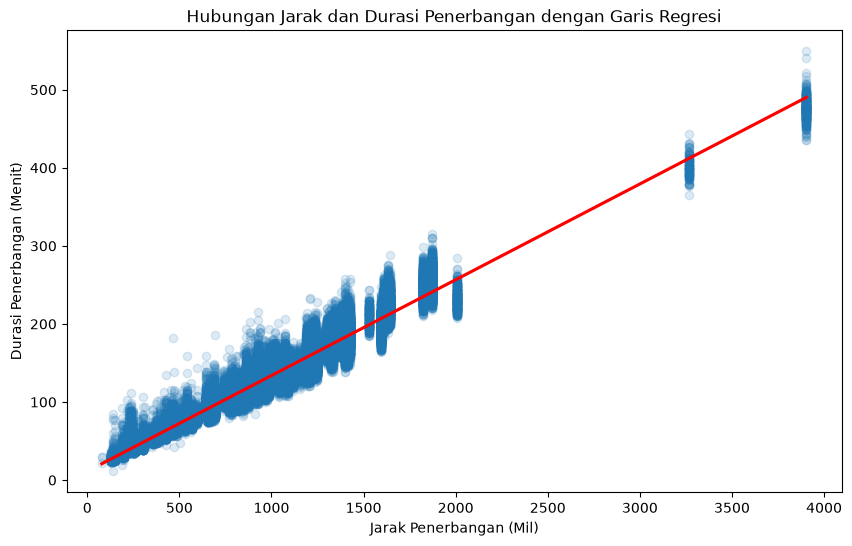

In [96]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 6))

# Membuat scatter plot dengan garis regresi
sns.regplot(
    data=flight_correlation_data,
    x='Distance',
    y='AirTime',
    scatter_kws={'alpha': 0.15},
    line_kws={'color': 'red'}
)

# Memberikan judul dan label grafik
plt.title('Hubungan Jarak dan Durasi Penerbangan dengan Garis Regresi')
plt.xlabel('Jarak Penerbangan (Mil)')
plt.ylabel('Durasi Penerbangan (Menit)')

# Menampilkan grafik
plt.show()

## Kesimpulan EDA Q3
Hasil analisis menunjukkan bahwa jarak penerbangan memiliki hubungan positif sangat kuat dengan durasi penerbangan. Hal ini dibuktikan melalui korelasi Pearson sebesar 0,9847 dan Spearman sebesar 0,9835. Visualisasi scatter plot juga memperlihatkan bahwa semakin jauh jarak penerbangan, semakin lama durasi yang dibutuhkan. Dengan demikian, jarak penerbangan memiliki hubungan yang sangat erat dengan waktu tempuh pesawat.

## Analisis Korelasi Antarvariabel Numerik

Analisis korelasi dilakukan untuk mengukur kekuatan dan arah hubungan linear antarvariabel numerik menggunakan koefisien **korelasi Pearson**.

**Data yang digunakan dalam korelasi:**

| Kolom | Alasan dipilih |
|---|---|
| DepDelay, ArrDelay | Variabel utama keterlambatan yang menjadi fokus analisis |
| Distance | Menguji apakah jarak memengaruhi keterlambatan dan durasi |
| AirTime, ActualElapsedTime | Menguji hubungan durasi dengan jarak dan keterlambatan |
| TaxiIn, TaxiOut | Menguji apakah waktu operasional di darat berkaitan dengan keterlambatan |

**Kolom yang tidak digunakan:**
- **Year** – hanya memiliki satu nilai (2011), sehingga korelasinya tidak dapat dihitung.
- **Month, DayofMonth, DayOfWeek** – merupakan kode kalender (kategorikal), bukan besaran kontinu.
- **DepTime, ArrTime** – berformat HHMM sehingga jaraknya tidak linear (contoh: 1259 ke 1300 hanya berselisih 1 menit).
- **FlightNum, TailNum** – merupakan identitas penerbangan/pesawat.
- **Cancelled, Diverted** – penanda status yang digunakan sebagai filter data.

**Filter data:** hanya penerbangan **normal** (Cancelled = 0 dan Diverted = 0) yang memiliki nilai lengkap pada seluruh kolom di atas, karena penerbangan yang dibatalkan atau dialihkan tidak memiliki nilai durasi dan keterlambatan kedatangan.

In [97]:
# Menentukan kolom numerik yang digunakan dalam analisis korelasi
correlation_columns = [
    'DepDelay', 'ArrDelay', 'Distance',
    'AirTime', 'ActualElapsedTime',
    'TaxiIn', 'TaxiOut'
]

# Mengambil penerbangan normal dengan data lengkap
correlation_data = df_clean[
    (df_clean['Cancelled'] == 0) &
    (df_clean['Diverted'] == 0)
][correlation_columns].dropna()

print("Jumlah data yang digunakan:", len(correlation_data))

# Menghitung matriks korelasi Pearson
correlation_matrix = correlation_data.corr(method='pearson')

# Menampilkan matriks korelasi
display(correlation_matrix.round(4))

Jumlah data yang digunakan: 223874


,DepDelay,ArrDelay,Distance,AirTime,ActualElapsedTime,TaxiIn,TaxiOut
DepDelay,1.0000,0.9292,0.0302,0.0275,0.0274,0.0141,0.0017
ArrDelay,0.9292,1.0000,-0.0044,0.0219,0.0556,0.0899,0.2202
Distance,0.0302,-0.0044,1.0000,0.9847,0.9744,0.2144,0.1585
AirTime,0.0275,0.0219,0.9847,1.0000,0.9889,0.2108,0.1605
ActualElapsedTime,0.0274,0.0556,0.9744,0.9889,1.0000,0.2810,0.2903
TaxiIn,0.0141,0.0899,0.2144,0.2108,0.2810,1.0000,0.1017
TaxiOut,0.0017,0.2202,0.1585,0.1605,0.2903,0.1017,1.0000


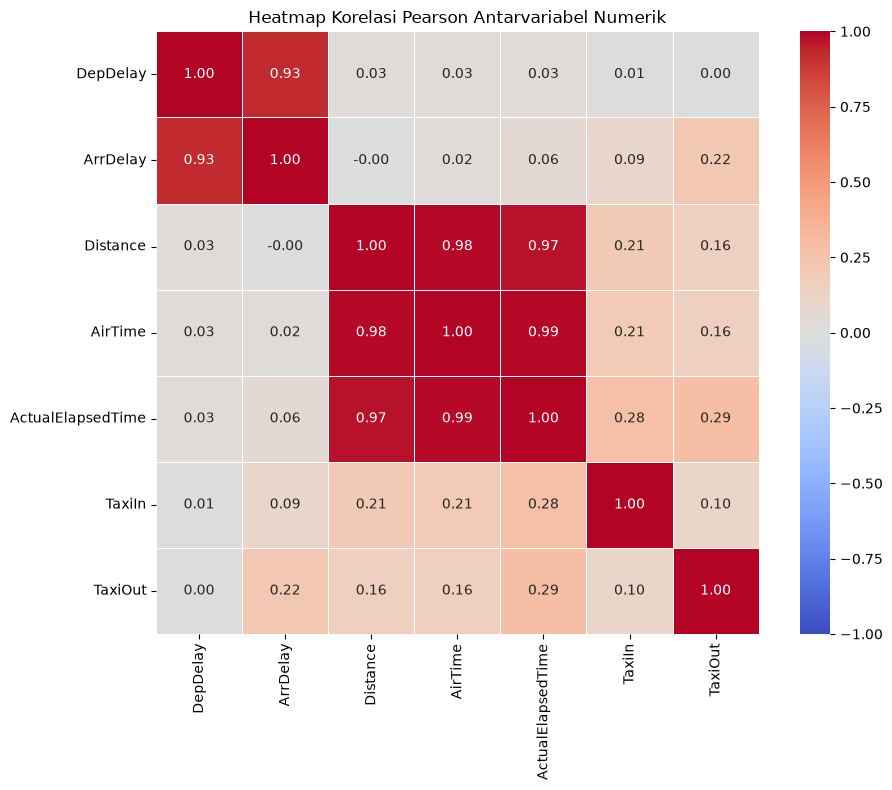

In [98]:
# Mengatur ukuran grafik
plt.figure(figsize=(10, 8))

# Membuat heatmap matriks korelasi
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

# Memberikan judul grafik
plt.title('Heatmap Korelasi Pearson Antarvariabel Numerik')

# Mengatur tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

In [99]:
# Fungsi interpretasi kekuatan korelasi (skala Sugiyono)
def interpret_correlation(r):
    r_abs = abs(r)
    if r_abs >= 0.8:
        strength = 'Sangat kuat'
    elif r_abs >= 0.6:
        strength = 'Kuat'
    elif r_abs >= 0.4:
        strength = 'Sedang'
    elif r_abs >= 0.2:
        strength = 'Lemah'
    else:
        strength = 'Sangat lemah'
    direction = 'Positif' if r > 0 else 'Negatif'
    return f'{direction} {strength.lower()}'

# Mengambil pasangan variabel unik (segitiga atas matriks)
mask = np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
correlation_pairs = (
    correlation_matrix.where(mask)
    .stack()
    .dropna()
    .reset_index()
)
correlation_pairs.columns = ['Variabel 1', 'Variabel 2', 'Korelasi']

# Mengurutkan berdasarkan kekuatan hubungan (nilai absolut)
correlation_pairs = correlation_pairs.reindex(
    correlation_pairs['Korelasi'].abs().sort_values(ascending=False).index
).reset_index(drop=True)

# Menambahkan interpretasi
correlation_pairs['Interpretasi'] = correlation_pairs['Korelasi'].apply(interpret_correlation)
correlation_pairs['Korelasi'] = correlation_pairs['Korelasi'].round(4)

# Menampilkan seluruh pasangan korelasi
display(correlation_pairs)

,Variabel 1,Variabel 2,Korelasi,Interpretasi
0,AirTime,ActualElapsedTime,0.9889,Positif sangat kuat
1,Distance,AirTime,0.9847,Positif sangat kuat
2,Distance,ActualElapsedTime,0.9744,Positif sangat kuat
3,DepDelay,ArrDelay,0.9292,Positif sangat kuat
4,ActualElapsedTime,TaxiOut,0.2903,Positif lemah
5,ActualElapsedTime,TaxiIn,0.2810,Positif lemah
6,ArrDelay,TaxiOut,0.2202,Positif lemah
7,Distance,TaxiIn,0.2144,Positif lemah
8,AirTime,TaxiIn,0.2108,Positif lemah
9,AirTime,TaxiOut,0.1605,Positif sangat lemah


### Kesimpulan Analisis Korelasi

Berdasarkan matriks korelasi Pearson terhadap 223.874 penerbangan normal, ditemukan tiga kelompok hubungan:

1. **Korelasi sangat kuat** terdapat pada kelompok jarak dan durasi, yaitu ActualElapsedTime–AirTime (0,99), AirTime–Distance (0,98), dan ActualElapsedTime–Distance (0,97). Hal ini wajar karena semakin jauh jarak penerbangan, semakin lama waktu tempuhnya. Selain itu, DepDelay–ArrDelay memiliki korelasi 0,93, yang berarti keterlambatan keberangkatan hampir selalu berlanjut menjadi keterlambatan kedatangan.
2. **Korelasi lemah** terdapat antara TaxiOut dengan ActualElapsedTime (0,29) dan ArrDelay (0,22), serta TaxiIn dengan ActualElapsedTime (0,28). Menariknya, TaxiOut berkorelasi lemah dengan ArrDelay tetapi hampir tidak berkorelasi dengan DepDelay (0,00), karena DepDelay dihitung saat pesawat meninggalkan gerbang, sebelum proses taxi berlangsung.
3. **Korelasi sangat lemah** terdapat antara jarak/durasi dengan keterlambatan, misalnya Distance–ArrDelay (−0,00) dan Distance–DepDelay (0,03). Artinya, jarak penerbangan tidak menentukan besar kecilnya keterlambatan.

Dengan demikian, faktor yang paling berkaitan dengan keterlambatan kedatangan adalah keterlambatan keberangkatan, sedangkan jarak dan durasi penerbangan tidak memiliki hubungan linear yang berarti dengan keterlambatan.

## Kesimpulan keseluruhan EDA
Berdasarkan hasil Exploratory Data Analysis, distribusi keterlambatan keberangkatan dan kedatangan cenderung miring ke kanan serta memiliki sejumlah outlier. Analisis korelasi menunjukkan hubungan positif sangat kuat antara keterlambatan keberangkatan dan kedatangan (0,9292). Selain itu, jarak penerbangan memiliki hubungan positif sangat kuat dengan durasi penerbangan (0,9847). Hasil EDA memberikan gambaran mengenai karakteristik, distribusi, dan hubungan antarvariabel yang dapat digunakan sebagai dasar untuk analisis lebih lanjut.

Analisis matriks korelasi juga menunjukkan bahwa jarak dan durasi penerbangan saling berkorelasi sangat kuat (0,97–0,99), sedangkan keduanya hampir tidak berkorelasi dengan keterlambatan. Faktor yang paling berkaitan dengan keterlambatan kedatangan adalah keterlambatan keberangkatan.

## Step 5 — Pemodelan (Modeling)

Pada tahap ini dibangun tiga jenis model sesuai rumusan masalah:

| No | Jenis Model | Target | Algoritma |
|---|---|---|---|
| 5.1 | **Klasifikasi** | Status kedatangan: terlambat > 15 menit (1) atau tidak (0) | Logistic Regression, Random Forest Classifier |
| 5.2 | **Prediksi (Regresi)** | Besar keterlambatan kedatangan `ArrDelay` (menit) | Linear Regression, Random Forest Regressor |
| 5.3 | **Pengelompokan** | Segmentasi bandara tujuan | K-Means Clustering |

**Data yang digunakan:** hanya penerbangan **normal** (Cancelled = 0 dan Diverted = 0), karena penerbangan yang dibatalkan atau dialihkan tidak memiliki nilai `ArrDelay` sebagai target. Data dibagi menjadi **80% data latih** dan **20% data uji** dengan `random_state=42` agar hasil dapat direproduksi.

**Batas 15 menit** digunakan karena merupakan standar FAA (Federal Aviation Administration) untuk menyatakan sebuah penerbangan *terlambat*.

In [100]:
# Mengimpor library pemodelan dan evaluasi
import time
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)

print("Library pemodelan berhasil diimport!")

Library pemodelan berhasil diimport!


### Feature Engineering

Dataset tidak memiliki kolom jadwal keberangkatan (*scheduled departure time*). Kolom `DepTime` adalah jam keberangkatan **aktual**, sehingga sudah mengandung informasi keterlambatan. Jika dipakai langsung, model akan "mencontek" jawaban (*data leakage*).

Oleh karena itu, jam jadwal keberangkatan dihitung kembali dengan rumus:

> **Jadwal keberangkatan = DepTime (dalam menit) − DepDelay**

Hasilnya diubah menjadi jam (0–23) pada kolom `SchedDepHour`. Selain itu dibuat kolom target:
- `IsDelayed` = 1 jika `ArrDelay` > 15 menit, dan 0 jika tidak (untuk klasifikasi).
- `ArrDelay` digunakan langsung sebagai target regresi.

In [101]:
# Mengambil penerbangan normal (tidak batal dan tidak dialihkan)
model_df = df_clean[
    (df_clean['Cancelled'] == 0) &
    (df_clean['Diverted'] == 0)
].copy()

# Mengubah DepTime (HHMM) menjadi menit sejak tengah malam
dep_minutes = (model_df['DepTime'] // 100) * 60 + (model_df['DepTime'] % 100)

# Menghitung jadwal keberangkatan = waktu aktual - keterlambatan
sched_minutes = (dep_minutes - model_df['DepDelay']) % (24 * 60)

# Mengubah menjadi jam jadwal keberangkatan (0-23)
model_df['SchedDepHour'] = (sched_minutes // 60).astype(int)

# Membuat target klasifikasi: terlambat lebih dari 15 menit
model_df['IsDelayed'] = (model_df['ArrDelay'] > 15).astype(int)

# Menampilkan ukuran data dan distribusi kelas target
print("Ukuran data pemodelan:", model_df.shape)
print("\nDistribusi kelas IsDelayed:")
class_dist = model_df['IsDelayed'].value_counts().rename(index={0: 'Tidak terlambat (0)', 1: 'Terlambat > 15 menit (1)'})
display(pd.DataFrame({
    'Jumlah': class_dist,
    'Persentase (%)': (class_dist / len(model_df) * 100).round(2)
}))

display(model_df[['DepTime', 'DepDelay', 'SchedDepHour', 'ArrDelay', 'IsDelayed']].head())

Ukuran data pemodelan: (223874, 23)

Distribusi kelas IsDelayed:


,Jumlah,Persentase (%)
IsDelayed,,
Tidak terlambat (0),179493,80.18
Terlambat > 15 menit (1),44381,19.82


,DepTime,DepDelay,SchedDepHour,ArrDelay,IsDelayed
0,1400.0,0.0,14,-10.0,0
1,1401.0,1.0,14,-9.0,0
2,1352.0,-8.0,14,-8.0,0
3,1403.0,3.0,14,3.0,0
4,1405.0,5.0,14,-3.0,0


### 5.1 Klasifikasi — Prediksi Status Keterlambatan Kedatangan

**Skenario:** penumpang atau maskapai ingin mengetahui peluang sebuah penerbangan terlambat **sebelum pesawat berangkat**, hanya dari informasi jadwal.

**Fitur yang digunakan:**

| Fitur | Jenis | Keterangan |
|---|---|---|
| Month, DayOfWeek, SchedDepHour | Numerik | Waktu jadwal penerbangan |
| Distance | Numerik | Jarak penerbangan |
| UniqueCarrier, Origin, Dest | Kategorikal | Maskapai, bandara asal, dan bandara tujuan |

`DepDelay`, `TaxiOut`, `TaxiIn`, `AirTime`, dan `ActualElapsedTime` **tidak digunakan** karena nilainya baru diketahui setelah pesawat berangkat atau mendarat.

**Preprocessing:** fitur numerik distandarisasi menggunakan `StandardScaler`, sedangkan fitur kategorikal diubah menggunakan `OneHotEncoder`. Karena kelas "terlambat" jumlahnya lebih sedikit (*imbalanced*), digunakan parameter `class_weight='balanced'` agar model tidak hanya menebak kelas mayoritas.

**Algoritma:**
- **Logistic Regression** sebagai model dasar (*baseline*) yang sederhana dan mudah diinterpretasikan.
- **Random Forest Classifier** sebagai model *ensemble* yang mampu menangkap hubungan non-linear antarfitur.

In [102]:
# Menentukan fitur dan target klasifikasi
clf_numeric = ['Month', 'DayOfWeek', 'SchedDepHour', 'Distance']
clf_categorical = ['UniqueCarrier', 'Origin', 'Dest']

X_clf = model_df[clf_numeric + clf_categorical]
y_clf = model_df['IsDelayed']

# Membagi data latih dan data uji (80:20) dengan proporsi kelas yang sama
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

print("Data latih:", X_train_c.shape)
print("Data uji  :", X_test_c.shape)

# Membuat tahapan preprocessing
clf_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), clf_numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), clf_categorical)
])

# Membuat dua model klasifikasi dalam bentuk pipeline
clf_models = {
    'Logistic Regression': Pipeline([
        ('preprocess', clf_preprocessor),
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    'Random Forest': Pipeline([
        ('preprocess', clf_preprocessor),
        ('model', RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=20,
            class_weight='balanced',
            n_jobs=-1,
            random_state=42
        ))
    ])
}

# Melatih setiap model
for name, pipeline in clf_models.items():
    start = time.time()
    pipeline.fit(X_train_c, y_train_c)
    print(f"{name} selesai dilatih dalam {time.time() - start:.1f} detik")

Data latih: (179099, 7)
Data uji  : (44775, 7)


Logistic Regression selesai dilatih dalam 0.7 detik


Random Forest selesai dilatih dalam 5.0 detik


#### Evaluasi Model Klasifikasi

Metrik evaluasi yang digunakan:
- **Accuracy** – proporsi prediksi yang benar dari seluruh data.
- **Precision** – dari penerbangan yang diprediksi terlambat, berapa persen yang benar-benar terlambat.
- **Recall** – dari penerbangan yang benar-benar terlambat, berapa persen yang berhasil dideteksi.
- **F1-Score** – rata-rata harmonik precision dan recall, cocok untuk data tidak seimbang.
- **ROC-AUC** – kemampuan model membedakan kelas terlambat dan tidak terlambat (0,5 = menebak acak, 1,0 = sempurna).

In [103]:
# Menghitung metrik evaluasi setiap model pada data uji
clf_results = []

for name, pipeline in clf_models.items():
    y_pred = pipeline.predict(X_test_c)
    y_proba = pipeline.predict_proba(X_test_c)[:, 1]

    clf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_c, y_pred),
        'Precision': precision_score(y_test_c, y_pred),
        'Recall': recall_score(y_test_c, y_pred),
        'F1-Score': f1_score(y_test_c, y_pred),
        'ROC-AUC': roc_auc_score(y_test_c, y_proba)
    })

clf_results = pd.DataFrame(clf_results).set_index('Model').round(4)
display(clf_results)

# Menentukan model terbaik berdasarkan ROC-AUC
best_clf_name = clf_results['ROC-AUC'].idxmax()
best_clf = clf_models[best_clf_name]
print("Model klasifikasi terbaik:", best_clf_name)

# Menampilkan laporan klasifikasi model terbaik
print("\nClassification Report -", best_clf_name)
print(classification_report(
    y_test_c, best_clf.predict(X_test_c),
    target_names=['Tidak terlambat', 'Terlambat > 15 menit']
))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.5880,0.2641,0.6035,0.3674,0.6271
Random Forest,0.6161,0.2848,0.6198,0.3903,0.6655


Model klasifikasi terbaik: Random Forest

Classification Report - Random Forest
                      precision    recall  f1-score   support

     Tidak terlambat       0.87      0.62      0.72     35899
Terlambat > 15 menit       0.28      0.62      0.39      8876

            accuracy                           0.62     44775
           macro avg       0.58      0.62      0.56     44775
        weighted avg       0.75      0.62      0.65     44775



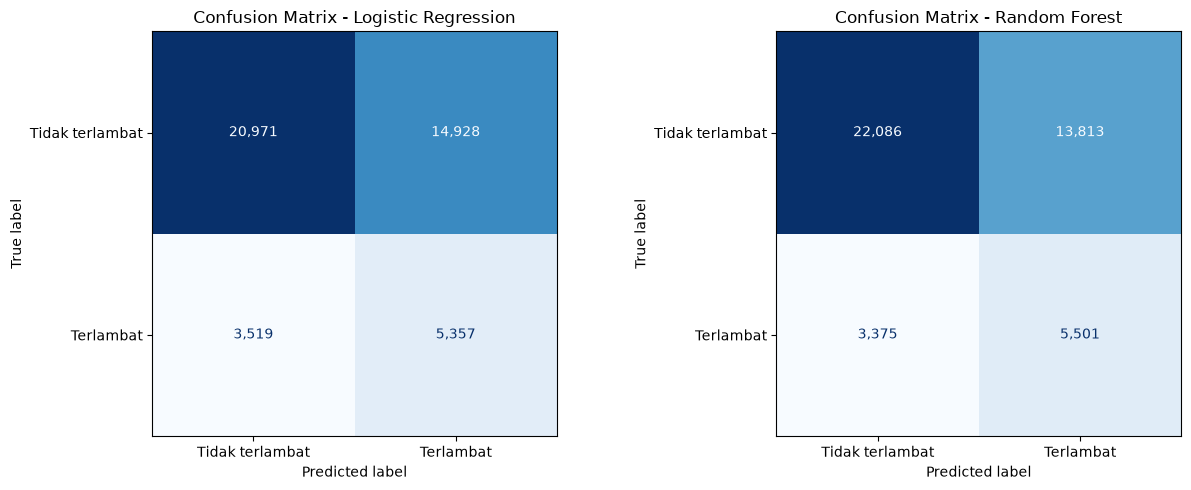

In [104]:
# Membuat confusion matrix untuk kedua model
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, pipeline) in zip(axes, clf_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline, X_test_c, y_test_c,
        display_labels=['Tidak terlambat', 'Terlambat'],
        cmap='Blues',
        values_format=',',
        ax=ax,
        colorbar=False
    )
    ax.set_title(f'Confusion Matrix - {name}')

plt.tight_layout()
plt.show()

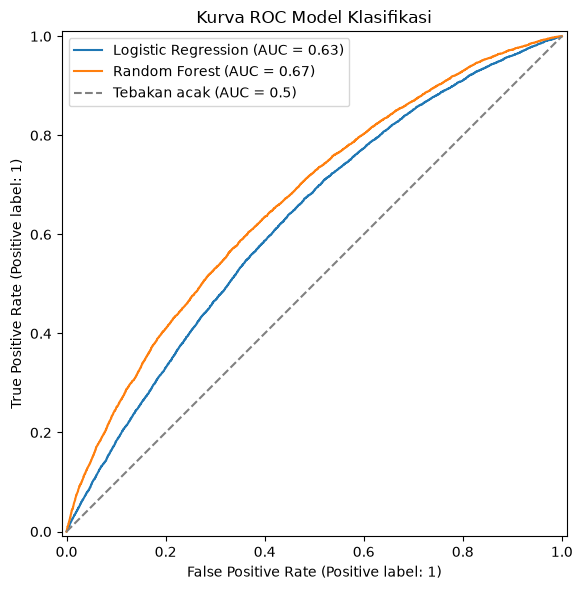

In [105]:
# Membuat kurva ROC untuk membandingkan kedua model
fig, ax = plt.subplots(figsize=(8, 6))

for name, pipeline in clf_models.items():
    RocCurveDisplay.from_estimator(pipeline, X_test_c, y_test_c, name=name, ax=ax)

# Garis acuan model acak
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Tebakan acak (AUC = 0.5)')

ax.set_title('Kurva ROC Model Klasifikasi')
ax.legend()
plt.tight_layout()
plt.show()

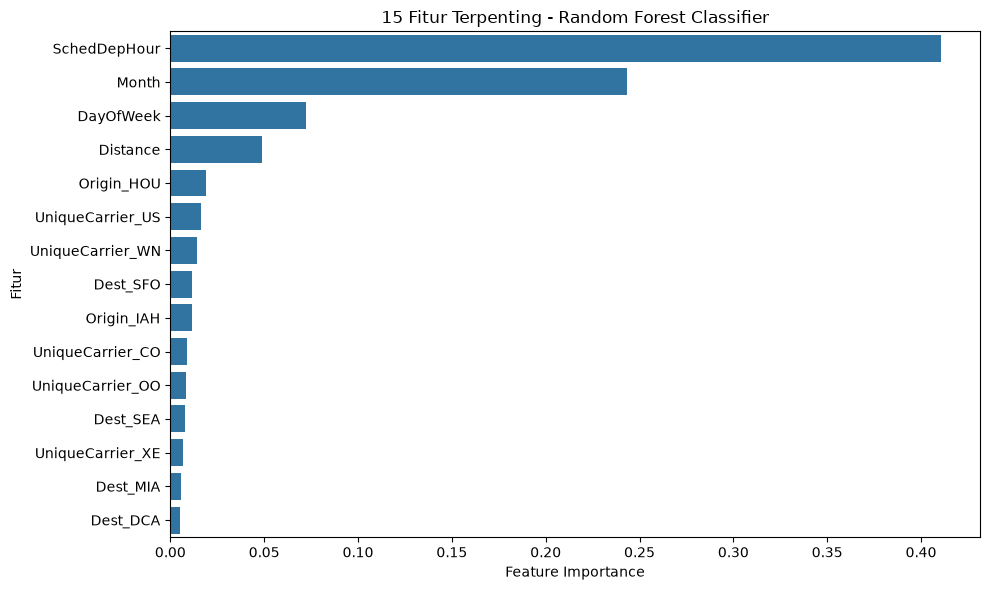

In [106]:
# Mengambil tingkat kepentingan fitur dari model Random Forest
rf_clf = clf_models['Random Forest']
feature_names = rf_clf.named_steps['preprocess'].get_feature_names_out()
importances = rf_clf.named_steps['model'].feature_importances_

clf_importance = pd.DataFrame({
    'Fitur': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15)

# Merapikan nama fitur
clf_importance['Fitur'] = (
    clf_importance['Fitur']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

# Visualisasi 15 fitur terpenting
plt.figure(figsize=(10, 6))
sns.barplot(data=clf_importance, x='Importance', y='Fitur')
plt.title('15 Fitur Terpenting - Random Forest Classifier')
plt.xlabel('Feature Importance')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

#### Kesimpulan Klasifikasi

Berdasarkan evaluasi pada 44.775 data uji, **Random Forest** menjadi model klasifikasi terbaik dengan ROC-AUC **0,6655**, F1-Score **0,3903**, Recall **0,6198**, Precision **0,2848**, dan Accuracy **0,6161**. Model ini mengungguli Logistic Regression (ROC-AUC 0,6271 dan F1-Score 0,3674) pada seluruh metrik.

Confusion matrix menunjukkan bahwa Random Forest berhasil mendeteksi **5.501 dari 8.876** penerbangan yang benar-benar terlambat (62%). Namun, model juga menghasilkan 13.813 *false alarm*, yaitu penerbangan tepat waktu yang diprediksi terlambat, sehingga precision masih rendah.

Accuracy bukan metrik utama pada kasus ini karena data tidak seimbang. Model yang selalu menebak "tidak terlambat" sudah memperoleh accuracy 80,18%, tetapi tidak mampu mendeteksi satu pun penerbangan terlambat (recall 0). Oleh karena itu, model dinilai menggunakan ROC-AUC, F1-Score, dan Recall.

Fitur paling berpengaruh adalah **jam jadwal keberangkatan (SchedDepHour)**, diikuti oleh **bulan (Month)**, **hari (DayOfWeek)**, dan **jarak (Distance)**. Hal ini sesuai dengan hasil analisis sebelumnya bahwa keterlambatan bervariasi menurut waktu. Penerbangan pada sore hingga malam hari cenderung lebih berisiko terlambat karena efek keterlambatan yang menumpuk sepanjang hari.

Performa model yang moderat (ROC-AUC 0,67) menunjukkan bahwa keterlambatan **sulit diprediksi hanya dari informasi jadwal**. Penyebab utama keterlambatan seperti cuaca, kepadatan lalu lintas udara, dan keterlambatan pesawat dari penerbangan sebelumnya tidak tersedia dalam dataset. Meskipun demikian, model ini tetap lebih baik daripada tebakan acak (ROC-AUC 0,5) dan dapat digunakan sebagai **indikator awal risiko keterlambatan**.

### 5.2 Prediksi (Regresi) — Prediksi Besar Keterlambatan Kedatangan

**Skenario:** setelah pesawat lepas landas, maskapai atau bandara tujuan ingin memperkirakan **berapa menit** pesawat akan terlambat tiba, sehingga dapat menyiapkan gerbang, kru darat, dan informasi bagi penumpang.

**Fitur yang digunakan:**

| Fitur | Jenis | Keterangan |
|---|---|---|
| DepDelay | Numerik | Keterlambatan keberangkatan (sudah diketahui setelah berangkat) |
| TaxiOut | Numerik | Waktu taxi sebelum lepas landas |
| Distance | Numerik | Jarak penerbangan |
| Month, DayOfWeek, SchedDepHour | Numerik | Waktu jadwal penerbangan |
| UniqueCarrier, Origin, Dest | Kategorikal | Maskapai, bandara asal, dan bandara tujuan |

`TaxiIn`, `AirTime`, dan `ActualElapsedTime` **tidak digunakan** karena baru diketahui setelah pesawat mendarat.

**Algoritma:**
- **Linear Regression** sebagai model dasar, sesuai hasil korelasi DepDelay–ArrDelay yang sangat kuat (0,93).
- **Random Forest Regressor** untuk menangkap pola non-linear.

Sebagai pembanding juga digunakan **baseline sederhana**, yaitu menganggap keterlambatan kedatangan sama dengan keterlambatan keberangkatan (`ArrDelay = DepDelay`). Model dianggap berguna jika mampu mengalahkan baseline ini.

In [107]:
# Menentukan fitur dan target regresi
reg_numeric = ['DepDelay', 'TaxiOut', 'Distance', 'Month', 'DayOfWeek', 'SchedDepHour']
reg_categorical = ['UniqueCarrier', 'Origin', 'Dest']

X_reg = model_df[reg_numeric + reg_categorical]
y_reg = model_df['ArrDelay']

# Membagi data latih dan data uji (80:20)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

print("Data latih:", X_train_r.shape)
print("Data uji  :", X_test_r.shape)

# Membuat tahapan preprocessing
reg_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), reg_numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), reg_categorical)
])

# Membuat dua model regresi dalam bentuk pipeline
reg_models = {
    'Linear Regression': Pipeline([
        ('preprocess', reg_preprocessor),
        ('model', LinearRegression())
    ]),
    'Random Forest': Pipeline([
        ('preprocess', reg_preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=50,
            max_depth=12,
            min_samples_leaf=50,
            max_features=0.5,
            n_jobs=-1,
            random_state=42
        ))
    ])
}

# Melatih setiap model
for name, pipeline in reg_models.items():
    start = time.time()
    pipeline.fit(X_train_r, y_train_r)
    print(f"{name} selesai dilatih dalam {time.time() - start:.1f} detik")

Data latih: (179099, 9)
Data uji  : (44775, 9)


Linear Regression selesai dilatih dalam 1.4 detik


Random Forest selesai dilatih dalam 9.9 detik


#### Evaluasi Model Regresi

Metrik evaluasi yang digunakan:
- **MAE (Mean Absolute Error)** – rata-rata selisih absolut antara prediksi dan nilai aktual (menit).
- **RMSE (Root Mean Squared Error)** – akar rata-rata kuadrat error; lebih sensitif terhadap error besar (menit).
- **R² (Koefisien Determinasi)** – proporsi variasi `ArrDelay` yang dapat dijelaskan oleh model (0–1, semakin besar semakin baik).

In [108]:
# Fungsi untuk menghitung metrik regresi
def regression_metrics(y_true, y_pred):
    return {
        'MAE (menit)': mean_absolute_error(y_true, y_pred),
        'RMSE (menit)': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

reg_results = {}

# Baseline: ArrDelay dianggap sama dengan DepDelay
reg_results['Baseline (ArrDelay = DepDelay)'] = regression_metrics(
    y_test_r, X_test_r['DepDelay']
)

# Evaluasi setiap model pada data uji
reg_predictions = {}
for name, pipeline in reg_models.items():
    reg_predictions[name] = pipeline.predict(X_test_r)
    reg_results[name] = regression_metrics(y_test_r, reg_predictions[name])

reg_results = pd.DataFrame(reg_results).T.round(4)
display(reg_results)

# Menentukan model terbaik berdasarkan RMSE terkecil
best_reg_name = reg_results.drop(index='Baseline (ArrDelay = DepDelay)')['RMSE (menit)'].idxmin()
best_reg = reg_models[best_reg_name]
print("Model regresi terbaik:", best_reg_name)

,MAE (menit),RMSE (menit),R2
Baseline (ArrDelay = DepDelay),8.4341,11.5922,0.8566
Linear Regression,5.9362,8.3484,0.9256
Random Forest,6.1730,9.8263,0.8969


Model regresi terbaik: Linear Regression


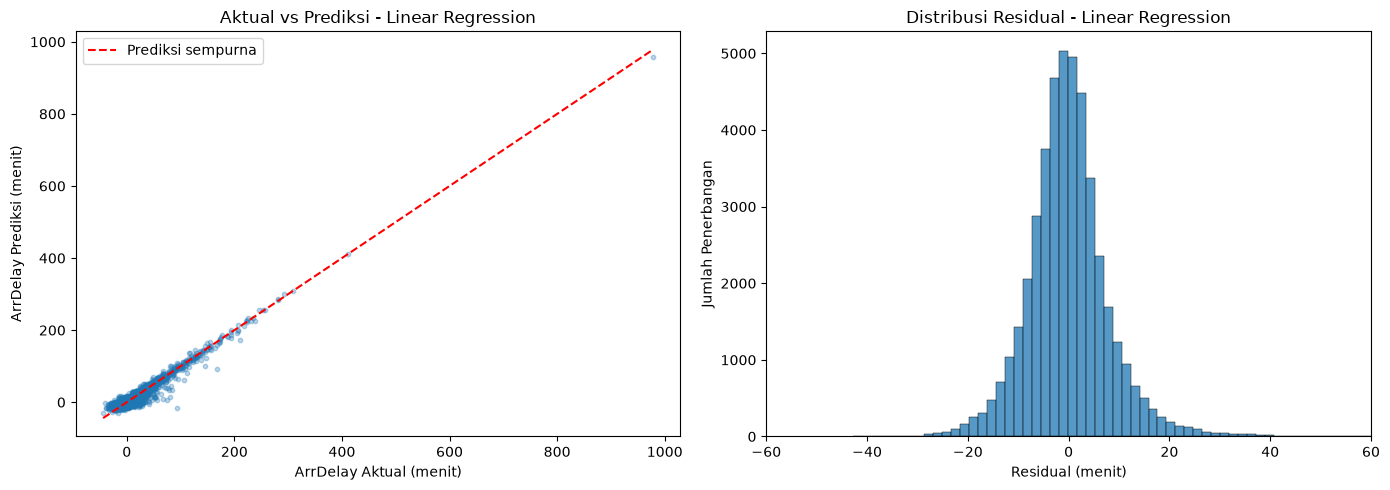

In [109]:
# Mengambil sampel data uji agar grafik tidak terlalu padat
sample_idx = np.random.RandomState(42).choice(len(y_test_r), size=5000, replace=False)
y_actual_sample = y_test_r.values[sample_idx]
y_pred_sample = reg_predictions[best_reg_name][sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot nilai aktual vs prediksi
axes[0].scatter(y_actual_sample, y_pred_sample, alpha=0.3, s=10)
lims = [min(y_actual_sample.min(), y_pred_sample.min()), max(y_actual_sample.max(), y_pred_sample.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', label='Prediksi sempurna')
axes[0].set_title(f'Aktual vs Prediksi - {best_reg_name}')
axes[0].set_xlabel('ArrDelay Aktual (menit)')
axes[0].set_ylabel('ArrDelay Prediksi (menit)')
axes[0].legend()

# Distribusi residual (selisih aktual - prediksi)
residuals = y_test_r.values - reg_predictions[best_reg_name]
sns.histplot(residuals, bins=100, ax=axes[1])
axes[1].set_xlim(-60, 60)
axes[1].set_title(f'Distribusi Residual - {best_reg_name}')
axes[1].set_xlabel('Residual (menit)')
axes[1].set_ylabel('Jumlah Penerbangan')

plt.tight_layout()
plt.show()

,Fitur,Importance
0,DepDelay,0.918821
1,TaxiOut,0.058150
2,SchedDepHour,0.007414
3,Month,0.005496
4,Distance,0.003870
5,UniqueCarrier_XE,0.001949
6,UniqueCarrier_CO,0.001493
7,DayOfWeek,0.000421
8,Origin_HOU,0.000412
9,UniqueCarrier_WN,0.000400


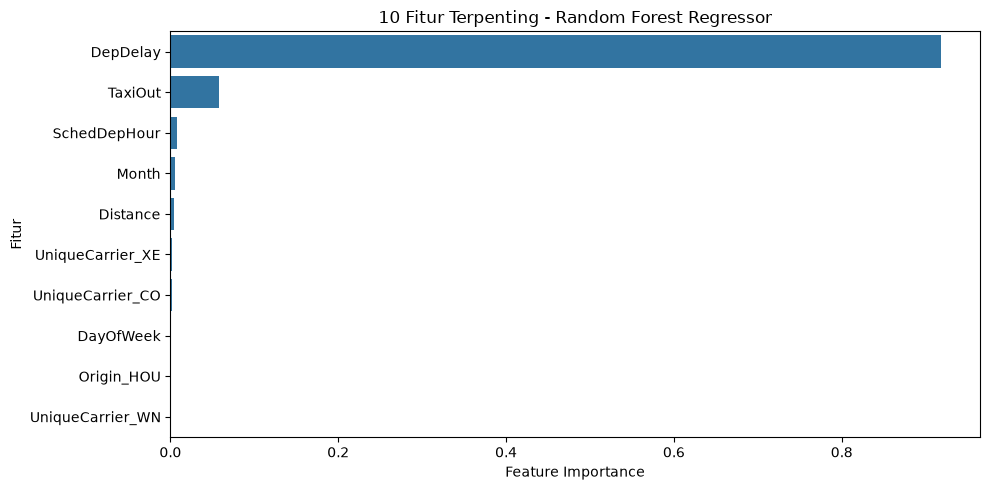

In [110]:
# Mengambil tingkat kepentingan fitur dari model Random Forest Regressor
rf_reg = reg_models['Random Forest']
reg_importance = pd.DataFrame({
    'Fitur': rf_reg.named_steps['preprocess'].get_feature_names_out(),
    'Importance': rf_reg.named_steps['model'].feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

reg_importance['Fitur'] = (
    reg_importance['Fitur']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

display(reg_importance.reset_index(drop=True))

# Visualisasi 10 fitur terpenting
plt.figure(figsize=(10, 5))
sns.barplot(data=reg_importance, x='Importance', y='Fitur')
plt.title('10 Fitur Terpenting - Random Forest Regressor')
plt.xlabel('Feature Importance')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

#### Kesimpulan Prediksi (Regresi)

Berdasarkan evaluasi pada 44.775 data uji, **Linear Regression** menjadi model prediksi terbaik dengan MAE **5,94 menit**, RMSE **8,35 menit**, dan R² **0,9256**. Artinya, model mampu menjelaskan sekitar **92,6%** variasi keterlambatan kedatangan, dengan rata-rata kesalahan prediksi sekitar 6 menit.

| Model | MAE (menit) | RMSE (menit) | R² |
|---|---|---|---|
| Baseline (ArrDelay = DepDelay) | 8,43 | 11,59 | 0,8566 |
| **Linear Regression** | **5,94** | **8,35** | **0,9256** |
| Random Forest | 6,17 | 9,83 | 0,8969 |

Linear Regression berhasil menurunkan RMSE sekitar **28%** dibandingkan baseline sederhana, sehingga penambahan fitur TaxiOut, jarak, waktu, maskapai, dan bandara terbukti meningkatkan akurasi prediksi. Linear Regression juga lebih baik daripada Random Forest karena hubungan antara keterlambatan keberangkatan dan kedatangan bersifat **linear** (korelasi 0,93). Selain itu, Random Forest dengan kedalaman terbatas kurang mampu memprediksi nilai keterlambatan ekstrem yang jarang muncul.

Grafik aktual vs prediksi menunjukkan titik-titik yang mengikuti garis prediksi sempurna, dan distribusi residual berpusat di sekitar 0 menit dengan sebagian besar error berada dalam rentang ±20 menit. Feature importance menunjukkan bahwa **DepDelay** merupakan fitur paling dominan, diikuti oleh **TaxiOut**. Hal ini konsisten dengan hasil analisis korelasi sebelumnya.

### 5.3 Pengelompokan (Clustering) — Segmentasi Bandara Tujuan

**Skenario:** maskapai dan bandara ingin mengelompokkan bandara tujuan yang memiliki karakteristik serupa, sehingga strategi operasional (penambahan jadwal, mitigasi keterlambatan) dapat disesuaikan per kelompok.

**Data yang digunakan:** seluruh penerbangan (termasuk yang dibatalkan untuk menghitung tingkat pembatalan), diringkas per bandara tujuan. Hanya bandara tujuan dengan **minimal 100 penerbangan** yang digunakan agar statistiknya stabil.

**Fitur per bandara tujuan:**

| Fitur | Keterangan |
|---|---|
| Log_Jumlah_Penerbangan | Logaritma jumlah penerbangan (dilog karena sangat miring ke kanan) |
| Rata_Jarak | Rata-rata jarak penerbangan (mil) |
| Rata_ArrDelay | Rata-rata keterlambatan kedatangan (menit) |
| Persen_Terlambat | Persentase penerbangan terlambat > 15 menit |
| Persen_Batal | Persentase penerbangan dibatalkan |

Seluruh fitur distandarisasi menggunakan `StandardScaler` karena K-Means berbasis jarak, sehingga fitur dengan skala besar (misalnya jarak) tidak mendominasi.

**Penentuan jumlah cluster (k)** menggunakan **Elbow Method** (inertia) dan **Silhouette Score**.

In [111]:
# Meringkas data per bandara tujuan
dest_df = df_clean.groupby('Dest').agg(
    Jumlah_Penerbangan=('FlightNum', 'count'),
    Rata_Jarak=('Distance', 'mean'),
    Rata_ArrDelay=('ArrDelay', 'mean'),
    Persen_Terlambat=('ArrDelay', lambda x: (x > 15).sum() / x.notna().sum() * 100),
    Persen_Batal=('Cancelled', lambda x: x.mean() * 100)
)

# Memilih bandara tujuan dengan minimal 100 penerbangan
dest_df = dest_df[dest_df['Jumlah_Penerbangan'] >= 100].copy()

# Transformasi logaritma pada jumlah penerbangan
dest_df['Log_Jumlah_Penerbangan'] = np.log10(dest_df['Jumlah_Penerbangan'])

print("Jumlah bandara tujuan yang dikelompokkan:", len(dest_df))
display(dest_df.round(2).head(10))

# Standarisasi fitur clustering
cluster_features = ['Log_Jumlah_Penerbangan', 'Rata_Jarak', 'Rata_ArrDelay', 'Persen_Terlambat', 'Persen_Batal']
cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(dest_df[cluster_features])

Jumlah bandara tujuan yang dikelompokkan: 112


,Jumlah_Penerbangan,Rata_Jarak,Rata_ArrDelay,Persen_Terlambat,Persen_Batal,Log_Jumlah_Penerbangan
Dest,,,,,,
ABQ,2812,749.44,7.23,20.83,0.89,3.45
AEX,724,190.00,5.84,16.06,1.66,2.86
AMA,1297,518.00,6.84,18.54,2.47,3.11
ANC,125,3266.00,26.08,45.16,0.00,2.10
ASE,125,913.73,6.79,19.64,4.00,2.10
ATL,7886,691.56,8.23,20.16,1.79,3.90
AUS,5022,142.67,7.45,18.53,0.54,3.70
AVL,350,834.00,9.97,21.39,0.86,2.54
BFL,504,1428.00,-13.20,8.15,0.20,2.70


,k,Inertia,Silhouette Score
0,2,434.5659,0.2410
1,3,348.9336,0.2622
2,4,292.7389,0.2447
3,5,246.1731,0.2347
4,6,216.9819,0.2229
5,7,197.5625,0.2317
6,8,173.1109,0.2327
7,9,153.0600,0.2460
8,10,144.6584,0.2238


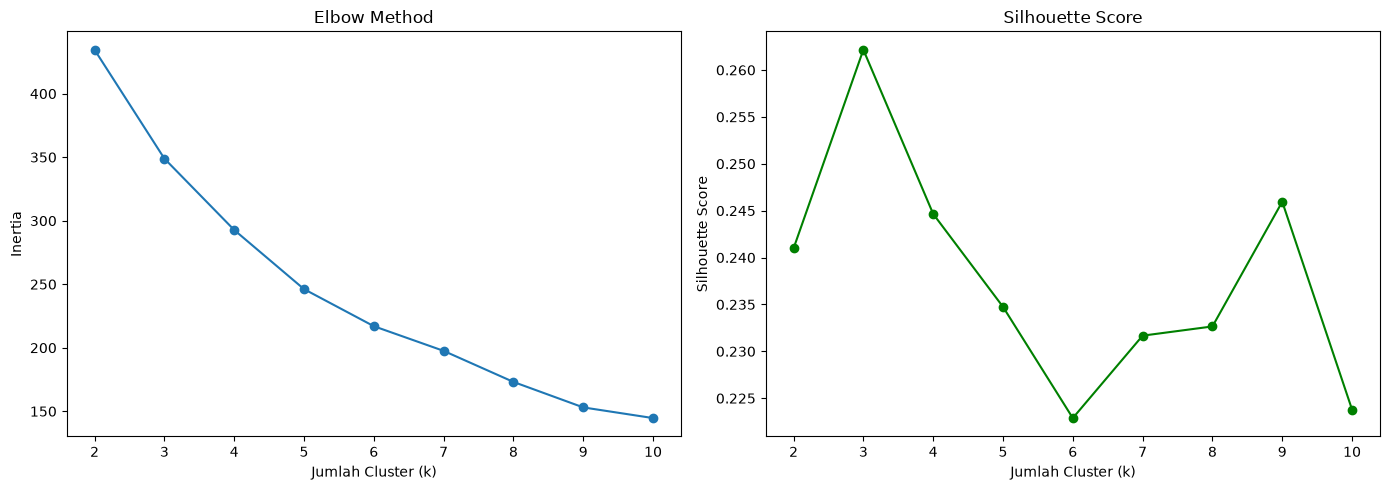

In [112]:
# Menghitung inertia dan silhouette score untuk k = 2 sampai 10
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))

k_evaluation = pd.DataFrame({
    'k': list(k_range),
    'Inertia': inertias,
    'Silhouette Score': silhouettes
}).round(4)
display(k_evaluation)

# Visualisasi Elbow Method dan Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Jumlah Cluster (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(list(k_range), silhouettes, marker='o', color='green')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Jumlah Cluster (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

In [113]:
# Menentukan jumlah cluster berdasarkan silhouette score tertinggi
best_k = int(k_evaluation.loc[k_evaluation['Silhouette Score'].idxmax(), 'k'])
print("Jumlah cluster yang digunakan:", best_k)

# Melatih model K-Means final
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
dest_df['Cluster'] = kmeans.fit_predict(X_cluster)

print("Silhouette Score:", round(silhouette_score(X_cluster, dest_df['Cluster']), 4))

# Profil setiap cluster
cluster_profile = dest_df.groupby('Cluster').agg(
    Jumlah_Bandara=('Rata_Jarak', 'count'),
    Rata_Jumlah_Penerbangan=('Jumlah_Penerbangan', 'mean'),
    Rata_Jarak=('Rata_Jarak', 'mean'),
    Rata_ArrDelay=('Rata_ArrDelay', 'mean'),
    Persen_Terlambat=('Persen_Terlambat', 'mean'),
    Persen_Batal=('Persen_Batal', 'mean')
).round(2)
display(cluster_profile)

# Contoh bandara pada setiap cluster (berdasarkan jumlah penerbangan terbanyak)
for c in sorted(dest_df['Cluster'].unique()):
    members = dest_df[dest_df['Cluster'] == c].sort_values('Jumlah_Penerbangan', ascending=False)
    print(f"Cluster {c} ({len(members)} bandara):", ', '.join(members.index[:12]))

Jumlah cluster yang digunakan: 3
Silhouette Score: 0.2622


,Jumlah_Bandara,Rata_Jumlah_Penerbangan,Rata_Jarak,Rata_ArrDelay,Persen_Terlambat,Persen_Batal
Cluster,,,,,,
0,23,1691.17,1112.67,1.08,14.25,0.63
1,22,823.18,1347.35,12.25,27.00,0.71
2,67,2542.64,680.31,7.41,19.96,1.56


Cluster 0 (23 bandara): PHX, LAS, TPA, SAN, DCA, BWI, MIA, FLL, CLE, SLC, PIT, SNA
Cluster 1 (22 bandara): SFO, SEA, PDX, TYS, CHS, RIC, VPS, SAV, ECP, ORF, OAK, GRR
Cluster 2 (67 bandara): DAL, ATL, MSY, DFW, LAX, DEN, ORD, AUS, SAT, CRP, CLT, EWR


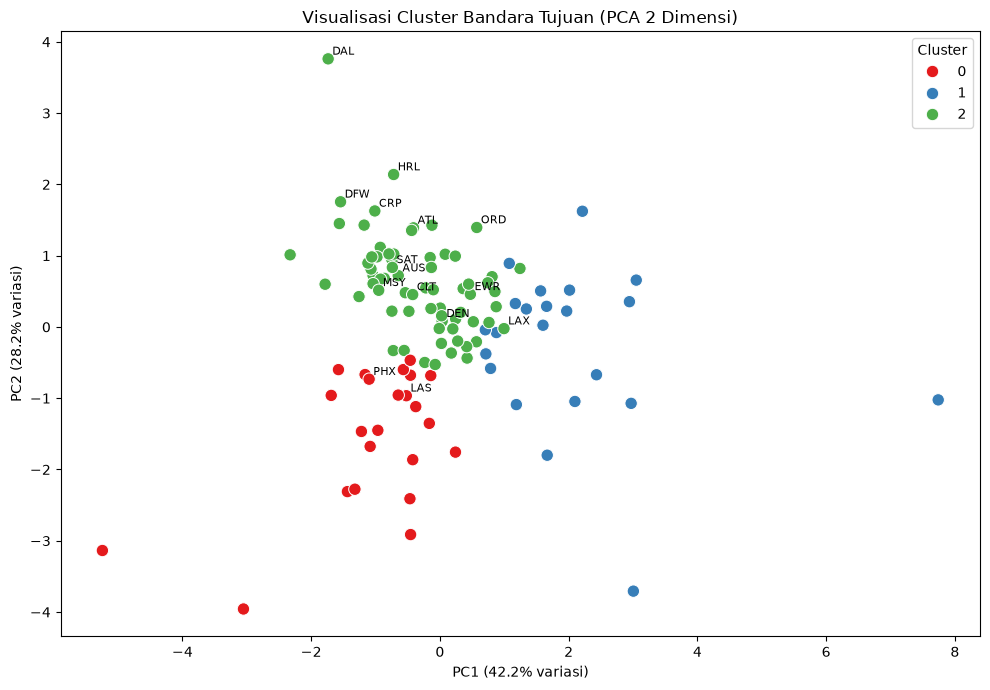

In [114]:
# Mereduksi 5 fitur menjadi 2 komponen utama untuk visualisasi
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=dest_df['Cluster'],
    palette='Set1',
    s=80
)

# Memberi label pada bandara dengan penerbangan terbanyak
top_dest = dest_df['Jumlah_Penerbangan'].nlargest(15).index
for i, dest in enumerate(dest_df.index):
    if dest in top_dest:
        plt.annotate(dest, (X_pca[i, 0], X_pca[i, 1]), fontsize=8, xytext=(3, 3), textcoords='offset points')

plt.title('Visualisasi Cluster Bandara Tujuan (PCA 2 Dimensi)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variasi)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variasi)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

#### Kesimpulan Pengelompokan (Clustering)

Berdasarkan Silhouette Score tertinggi (**0,2622**), jumlah cluster terbaik adalah **k = 3**. Grafik Elbow juga menunjukkan penurunan inertia yang mulai melandai setelah k = 3. Nilai silhouette sebesar 0,26 menunjukkan struktur cluster yang cukup terbentuk, meskipun masih terdapat sebagian bandara yang berada di perbatasan antar-cluster.

| Cluster | Jumlah Bandara | Rata-rata Penerbangan | Rata-rata Jarak (mil) | Rata-rata ArrDelay (menit) | % Terlambat | % Batal | Karakteristik |
|---|---|---|---|---|---|---|---|
| 0 | 23 | 1.691 | 1.113 | 1,08 | 14,25% | 0,63% | **Rute tepat waktu** – jarak menengah-jauh, keterlambatan paling rendah |
| 1 | 22 | 823 | 1.347 | 12,25 | 27,00% | 0,71% | **Rute rawan terlambat** – jarak terjauh, keterlambatan paling tinggi |
| 2 | 67 | 2.543 | 680 | 7,41 | 19,96% | 1,56% | **Rute padat jarak dekat-menengah** – volume penerbangan tertinggi, tingkat pembatalan tertinggi |

- **Cluster 0 (Rute tepat waktu):** contohnya PHX, LAS, TPA, SAN, DCA, BWI, dan MIA. Rute ini dapat dijadikan acuan kinerja operasional yang baik.
- **Cluster 1 (Rute rawan terlambat):** contohnya SFO, SEA, PDX, dan beberapa bandara regional di wilayah timur seperti TYS, CHS, dan RIC. Rute ini perlu mendapat prioritas mitigasi keterlambatan, misalnya penambahan waktu cadangan (*buffer*) pada jadwal.
- **Cluster 2 (Rute padat):** contohnya DAL, ATL, MSY, DFW, ORD, DEN, dan AUS. Rute ini memiliki frekuensi penerbangan tertinggi, sehingga gangguan kecil dapat berdampak pada banyak penumpang. Tingkat pembatalan yang lebih tinggi juga perlu diperhatikan.

Visualisasi PCA dua dimensi, yang menjelaskan sekitar 70% variasi data, memperlihatkan ketiga cluster terpisah cukup jelas. Dengan demikian, clustering berhasil membagi bandara tujuan menjadi kelompok yang dapat ditindaklanjuti secara operasional.

### 5.4 Ringkasan Evaluasi Model

| Jenis Model | Model Terbaik | Metrik Utama | Hasil | Interpretasi |
|---|---|---|---|---|
| Klasifikasi | Random Forest Classifier | ROC-AUC / F1 / Recall | 0,6655 / 0,3903 / 0,6198 | Cukup (moderat): mampu mendeteksi 62% penerbangan terlambat hanya dari informasi jadwal |
| Prediksi (Regresi) | Linear Regression | R² / MAE / RMSE | 0,9256 / 5,94 / 8,35 menit | Sangat baik: menjelaskan 92,6% variasi keterlambatan kedatangan |
| Pengelompokan | K-Means (k = 3) | Silhouette Score | 0,2622 | Cukup: tiga segmen bandara tujuan dengan karakteristik berbeda |

Perbedaan performa antara model klasifikasi dan regresi disebabkan oleh **informasi yang tersedia**. Model regresi memanfaatkan `DepDelay`, yang menurut analisis korelasi sangat kuat hubungannya dengan `ArrDelay` (0,93). Sebaliknya, model klasifikasi hanya menggunakan informasi jadwal sebelum keberangkatan, sehingga tugas prediksinya jauh lebih sulit.

## Step 6 — Deployment Model

Deployment dilakukan dengan cara:
1. **Menyimpan model** terbaik (beserta tahapan preprocessing di dalam pipeline) ke file `.joblib` menggunakan `joblib`.
2. **Memuat kembali model** dari file, seolah-olah digunakan pada aplikasi atau sesi baru.
3. **Menyediakan fungsi prediksi** yang menerima input sederhana (maskapai, rute, tanggal, jam) dan mengembalikan hasil prediksi.
4. **Form interaktif** menggunakan `ipywidgets` agar model dapat dicoba langsung di Google Colab tanpa menulis kode.

Karena preprocessing sudah berada di dalam pipeline, data baru cukup diberikan dalam bentuk mentah tanpa perlu di-scaling atau di-encoding secara manual.

In [115]:
import os

# Membuat folder untuk menyimpan model
os.makedirs('models', exist_ok=True)

# Menyimpan informasi pendukung: jarak rata-rata setiap rute
route_distance = model_df.groupby(['Origin', 'Dest'])['Distance'].median().to_dict()

# Menyimpan model dan informasi pendukung
joblib.dump(best_clf, 'models/model_klasifikasi.joblib', compress=3)
joblib.dump(best_reg, 'models/model_regresi.joblib', compress=3)
joblib.dump({
    'kmeans': kmeans,
    'scaler': cluster_scaler,
    'features': cluster_features
}, 'models/model_clustering.joblib', compress=3)
joblib.dump({
    'route_distance': route_distance,
    'carriers': sorted(model_df['UniqueCarrier'].unique()),
    'origins': sorted(model_df['Origin'].unique()),
    'destinations': sorted(model_df['Dest'].unique())
}, 'models/metadata.joblib')

# Menampilkan file yang tersimpan
for file in sorted(os.listdir('models')):
    size_mb = os.path.getsize(os.path.join('models', file)) / (1024 * 1024)
    print(f"{file:30s} {size_mb:8.2f} MB")

metadata.joblib                    0.00 MB
model_clustering.joblib            0.00 MB
model_klasifikasi.joblib           2.65 MB
model_regresi.joblib               0.00 MB


In [116]:
# Memuat kembali model dari file (simulasi penggunaan pada aplikasi baru)
loaded_clf = joblib.load('models/model_klasifikasi.joblib')
loaded_reg = joblib.load('models/model_regresi.joblib')
loaded_meta = joblib.load('models/metadata.joblib')

day_names_id = {1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu', 7: 'Minggu'}


def prediksi_penerbangan(carrier, origin, dest, month, day_of_week, sched_dep_hour,
                         dep_delay=None, taxi_out=None):
    """Memprediksi keterlambatan sebuah penerbangan.

    - Sebelum berangkat  : isi carrier, origin, dest, month, day_of_week, sched_dep_hour.
    - Setelah berangkat  : tambahkan dep_delay dan taxi_out untuk prediksi menit keterlambatan.
    """
    distance = loaded_meta['route_distance'].get((origin, dest))
    if distance is None:
        raise ValueError(f"Rute {origin} -> {dest} tidak ditemukan pada data latih.")

    data = pd.DataFrame([{
        'Month': month,
        'DayOfWeek': day_of_week,
        'SchedDepHour': sched_dep_hour,
        'Distance': distance,
        'UniqueCarrier': carrier,
        'Origin': origin,
        'Dest': dest
    }])

    # Prediksi klasifikasi (sebelum berangkat)
    # Catatan: model dilatih dengan class_weight='balanced', sehingga nilai ini adalah
    # skor risiko relatif (ambang 50%), bukan peluang absolut keterlambatan.
    prob = loaded_clf.predict_proba(data[clf_numeric + clf_categorical])[0, 1]
    hasil = {
        'Rute': f"{origin} -> {dest} ({distance:.0f} mil)",
        'Maskapai': carrier,
        'Jadwal': f"Bulan {month}, {day_names_id[day_of_week]}, jam {sched_dep_hour:02d}:00",
        'Skor risiko terlambat': f"{prob * 100:.1f}%",
        'Status prediksi': 'TERLAMBAT' if prob >= 0.5 else 'TEPAT WAKTU'
    }

    # Prediksi regresi (setelah berangkat)
    if dep_delay is not None and taxi_out is not None:
        data['DepDelay'] = dep_delay
        data['TaxiOut'] = taxi_out
        arr_delay = loaded_reg.predict(data[reg_numeric + reg_categorical])[0]
        hasil['Prediksi ArrDelay (menit)'] = round(float(arr_delay), 1)

    return hasil


# Contoh penggunaan pada beberapa penerbangan baru
contoh = [
    dict(carrier='CO', origin='IAH', dest='ORD', month=7, day_of_week=5, sched_dep_hour=18),
    dict(carrier='WN', origin='HOU', dest='DAL', month=11, day_of_week=3, sched_dep_hour=7),
    dict(carrier='XE', origin='IAH', dest='ATL', month=5, day_of_week=4, sched_dep_hour=17,
         dep_delay=45, taxi_out=25),
]

display(pd.DataFrame([prediksi_penerbangan(**c) for c in contoh]))

,Rute,Maskapai,Jadwal,Skor risiko terlambat,Status prediksi,Prediksi ArrDelay (menit)
0,IAH -> ORD (925 mil),CO,"Bulan 7, Jumat, jam 18:00",58.7%,TERLAMBAT,NaN
1,HOU -> DAL (239 mil),WN,"Bulan 11, Rabu, jam 07:00",29.0%,TEPAT WAKTU,NaN
2,IAH -> ATL (689 mil),XE,"Bulan 5, Kamis, jam 17:00",59.9%,TERLAMBAT,53.5


In [117]:
# Form interaktif untuk mencoba model (berjalan di Google Colab / Jupyter)
try:
    import ipywidgets as widgets
    from IPython.display import clear_output

    w_carrier = widgets.Dropdown(options=loaded_meta['carriers'], value='CO', description='Maskapai')
    w_origin = widgets.Dropdown(options=loaded_meta['origins'], value='IAH', description='Asal')
    w_dest = widgets.Dropdown(options=loaded_meta['destinations'], value='ORD', description='Tujuan')
    w_month = widgets.IntSlider(value=7, min=1, max=12, description='Bulan')
    w_day = widgets.Dropdown(options=[(v, k) for k, v in day_names_id.items()], value=5, description='Hari')
    w_hour = widgets.IntSlider(value=18, min=0, max=23, description='Jam')
    w_depdelay = widgets.IntText(value=0, description='DepDelay')
    w_taxiout = widgets.IntText(value=15, description='TaxiOut')
    w_button = widgets.Button(description='Prediksi', button_style='primary')
    w_output = widgets.Output()

    def on_click(_):
        with w_output:
            clear_output()
            try:
                hasil = prediksi_penerbangan(
                    w_carrier.value, w_origin.value, w_dest.value,
                    w_month.value, w_day.value, w_hour.value,
                    dep_delay=w_depdelay.value, taxi_out=w_taxiout.value
                )
                display(pd.Series(hasil).to_frame('Hasil'))
            except ValueError as e:
                print(e)

    w_button.on_click(on_click)

    display(widgets.VBox([
        widgets.HBox([w_carrier, w_origin, w_dest]),
        widgets.HBox([w_month, w_day, w_hour]),
        widgets.HBox([w_depdelay, w_taxiout]),
        w_button, w_output
    ]))
except ImportError:
    print("ipywidgets tidak tersedia. Gunakan fungsi prediksi_penerbangan() secara langsung.")

ipywidgets tidak tersedia. Gunakan fungsi prediksi_penerbangan() secara langsung.


### Kesimpulan Deployment

Model klasifikasi, regresi, dan clustering telah disimpan ke folder `models/` dalam format `.joblib`, lalu berhasil dimuat kembali dan digunakan untuk memprediksi data penerbangan baru. Fungsi `prediksi_penerbangan()` hanya membutuhkan input sederhana (maskapai, bandara asal dan tujuan, bulan, hari, dan jam jadwal), sedangkan jarak rute diambil otomatis dari metadata. Jika keterlambatan keberangkatan dan waktu taxi sudah diketahui, fungsi tersebut juga mengembalikan perkiraan menit keterlambatan kedatangan.

Form interaktif `ipywidgets` memungkinkan pengguna mencoba model langsung di Google Colab. File model di folder `models/` juga dapat diunduh dan digunakan kembali pada aplikasi lain, misalnya aplikasi web berbasis Streamlit atau API berbasis Flask/FastAPI, cukup dengan `joblib.load()`.

## Kesimpulan Akhir

Berdasarkan seluruh tahapan analisis dan pemodelan, rumusan masalah dapat dijawab sebagai berikut:

1. **Struktur dan kualitas data:** Dataset terdiri dari 227.496 penerbangan dan 21 kolom tanpa duplikasi maupun nilai tidak valid. Missing values hanya terdapat pada penerbangan yang dibatalkan atau dialihkan, sehingga dipertahankan tanpa imputasi. Outlier juga dipertahankan karena mencerminkan kondisi operasional yang sebenarnya.
2. **EDA Q1:** Distribusi keterlambatan keberangkatan dan kedatangan miring ke kanan, dengan median 0 menit dan rata-rata 9,44 menit (keberangkatan) serta 7,09 menit (kedatangan).
3. **EDA Q2:** Keterlambatan keberangkatan dan kedatangan memiliki hubungan positif sangat kuat (Pearson 0,9292).
4. **EDA Q3:** Jarak dan durasi penerbangan memiliki hubungan positif sangat kuat (Pearson 0,9847).
5. **Korelasi:** Kelompok jarak dan durasi saling berkorelasi sangat kuat (0,97–0,99), tetapi hampir tidak berkorelasi dengan keterlambatan. Faktor yang paling berkaitan dengan keterlambatan kedatangan adalah keterlambatan keberangkatan.
6. **Klasifikasi:** Random Forest mampu memprediksi status keterlambatan sebelum berangkat dengan ROC-AUC 0,6655 dan Recall 62%. Jam jadwal keberangkatan dan bulan merupakan faktor paling berpengaruh.
7. **Prediksi (Regresi):** Linear Regression memprediksi menit keterlambatan kedatangan setelah pesawat berangkat dengan R² 0,9256 dan MAE 5,94 menit, lebih baik 28% (RMSE) dibandingkan baseline.
8. **Pengelompokan:** K-Means membagi 112 bandara tujuan menjadi 3 cluster, yaitu rute tepat waktu, rute rawan terlambat, dan rute padat jarak dekat-menengah.
9. **Deployment:** Model disimpan dalam format `.joblib`, dapat dimuat kembali, dan digunakan melalui fungsi `prediksi_penerbangan()` serta form interaktif di Google Colab.

**Saran:** Untuk meningkatkan performa model klasifikasi, dapat ditambahkan data eksternal seperti kondisi cuaca, kepadatan lalu lintas udara, dan riwayat keterlambatan pesawat pada penerbangan sebelumnya (berdasarkan TailNum). Selain itu, dapat dicoba algoritma lain seperti Gradient Boosting atau XGBoost, serta penyetelan hyperparameter menggunakan cross-validation.